In [4]:
# Day38 - DATA CLEANING
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
df = pd.read_csv("Customer_Churn_Prediction_8000_Records.csv")
df

,CustomerID,Gender,SeniorCitizen,Partner,Dependents,TenureMonths,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaymentMethod,MonthlyCharges,TotalCharges,SupportCallsLast90Days,ComplaintRaised,AvgMonthlyDataUsageGB,AvgMonthlyCalls,SatisfactionScore,DaysSinceLastContact,Churn
0,CUST000001,Male,1,Yes,No,4,Yes,Yes,DSL,Yes,...,Electronic check,94.35,351.35,1,No,105.3,121,5.0,25.0,No
1,CUST000002,Male,1,Yes,Yes,35,Yes,Yes,DSL,Yes,...,Electronic check,92.29,3262.00,0,Yes,23.0,115,2.0,4.0,No
2,CUST000003,Female,0,No,No,51,Yes,No,DSL,No,...,Electronic check,82.09,4197.33,0,No,53.6,156,2.0,26.0,No
3,CUST000004,Male,0,No,Yes,42,Yes,Yes,Fiber optic,No,...,Credit card (automatic),107.06,4495.48,0,No,114.9,78,5.0,1.0,No
4,CUST000005,Male,1,No,No,30,Yes,Yes,Fiber optic,No,...,Credit card (automatic),100.78,3000.68,3,No,61.7,65,2.0,48.0,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,CUST007996,Male,0,No,No,21,No,No phone service,Fiber optic,Yes,...,Bank transfer (automatic),94.95,2039.03,0,No,26.9,0,5.0,102.0,No
7996,CUST007997,Female,0,No,No,5,Yes,Yes,5G Home,Yes,...,Credit card (automatic),95.78,431.26,1,No,30.6,98,2.0,3.0,No
7997,CUST007998,Female,0,No,No,15,Yes,Yes,DSL,No,...,Electronic check,87.89,1341.59,0,No,28.6,85,4.0,NaN,No
7998,CUST007999,Male,1,No,No,22,Yes,No,No,No internet service,...,Bank transfer (automatic),34.09,733.64,0,No,0.0,80,3.0,8.0,No


In [6]:
df .info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 27 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              8000 non-null   str    
 1   Gender                  8000 non-null   str    
 2   SeniorCitizen           8000 non-null   int64  
 3   Partner                 8000 non-null   str    
 4   Dependents              8000 non-null   str    
 5   TenureMonths            8000 non-null   int64  
 6   PhoneService            8000 non-null   str    
 7   MultipleLines           8000 non-null   str    
 8   InternetService         8000 non-null   str    
 9   OnlineSecurity          8000 non-null   str    
 10  OnlineBackup            7938 non-null   str    
 11  DeviceProtection        8000 non-null   str    
 12  TechSupport             8000 non-null   str    
 13  StreamingTV             8000 non-null   str    
 14  StreamingMovies         8000 non-null   str    
 15

In [7]:
df.describe().round()
df

,CustomerID,Gender,SeniorCitizen,Partner,Dependents,TenureMonths,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaymentMethod,MonthlyCharges,TotalCharges,SupportCallsLast90Days,ComplaintRaised,AvgMonthlyDataUsageGB,AvgMonthlyCalls,SatisfactionScore,DaysSinceLastContact,Churn
0,CUST000001,Male,1,Yes,No,4,Yes,Yes,DSL,Yes,...,Electronic check,94.35,351.35,1,No,105.3,121,5.0,25.0,No
1,CUST000002,Male,1,Yes,Yes,35,Yes,Yes,DSL,Yes,...,Electronic check,92.29,3262.00,0,Yes,23.0,115,2.0,4.0,No
2,CUST000003,Female,0,No,No,51,Yes,No,DSL,No,...,Electronic check,82.09,4197.33,0,No,53.6,156,2.0,26.0,No
3,CUST000004,Male,0,No,Yes,42,Yes,Yes,Fiber optic,No,...,Credit card (automatic),107.06,4495.48,0,No,114.9,78,5.0,1.0,No
4,CUST000005,Male,1,No,No,30,Yes,Yes,Fiber optic,No,...,Credit card (automatic),100.78,3000.68,3,No,61.7,65,2.0,48.0,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,CUST007996,Male,0,No,No,21,No,No phone service,Fiber optic,Yes,...,Bank transfer (automatic),94.95,2039.03,0,No,26.9,0,5.0,102.0,No
7996,CUST007997,Female,0,No,No,5,Yes,Yes,5G Home,Yes,...,Credit card (automatic),95.78,431.26,1,No,30.6,98,2.0,3.0,No
7997,CUST007998,Female,0,No,No,15,Yes,Yes,DSL,No,...,Electronic check,87.89,1341.59,0,No,28.6,85,4.0,NaN,No
7998,CUST007999,Male,1,No,No,22,Yes,No,No,No internet service,...,Bank transfer (automatic),34.09,733.64,0,No,0.0,80,3.0,8.0,No


In [8]:
df.isnull().sum()


CustomerID                  0
Gender                      0
SeniorCitizen               0
Partner                     0
Dependents                  0
TenureMonths                0
PhoneService                0
MultipleLines               0
InternetService             0
OnlineSecurity              0
OnlineBackup               62
DeviceProtection            0
TechSupport                 0
StreamingTV                 0
StreamingMovies             0
ContractType                0
PaperlessBilling            0
PaymentMethod               0
MonthlyCharges              0
TotalCharges                0
SupportCallsLast90Days      0
ComplaintRaised             0
AvgMonthlyDataUsageGB     101
AvgMonthlyCalls             0
SatisfactionScore         202
DaysSinceLastContact       99
Churn                       0
dtype: int64

In [9]:
missing_count = df.isnull().sum() 
print(missing_count) 


CustomerID                  0
Gender                      0
SeniorCitizen               0
Partner                     0
Dependents                  0
TenureMonths                0
PhoneService                0
MultipleLines               0
InternetService             0
OnlineSecurity              0
OnlineBackup               62
DeviceProtection            0
TechSupport                 0
StreamingTV                 0
StreamingMovies             0
ContractType                0
PaperlessBilling            0
PaymentMethod               0
MonthlyCharges              0
TotalCharges                0
SupportCallsLast90Days      0
ComplaintRaised             0
AvgMonthlyDataUsageGB     101
AvgMonthlyCalls             0
SatisfactionScore         202
DaysSinceLastContact       99
Churn                       0
dtype: int64


In [10]:
missing_percentage = ( df.isnull().sum() / len(df) ) * 100
print(missing_percentage)


CustomerID                0.0000
Gender                    0.0000
SeniorCitizen             0.0000
Partner                   0.0000
Dependents                0.0000
TenureMonths              0.0000
PhoneService              0.0000
MultipleLines             0.0000
InternetService           0.0000
OnlineSecurity            0.0000
OnlineBackup              0.7750
DeviceProtection          0.0000
TechSupport               0.0000
StreamingTV               0.0000
StreamingMovies           0.0000
ContractType              0.0000
PaperlessBilling          0.0000
PaymentMethod             0.0000
MonthlyCharges            0.0000
TotalCharges              0.0000
SupportCallsLast90Days    0.0000
ComplaintRaised           0.0000
AvgMonthlyDataUsageGB     1.2625
AvgMonthlyCalls           0.0000
SatisfactionScore         2.5250
DaysSinceLastContact      1.2375
Churn                     0.0000
dtype: float64


In [11]:
df.shape

(8000, 27)

In [12]:
df[df.duplicated()].shape

(0, 27)

In [13]:
df['CustomerID'].value_counts().head(1000)

CustomerID
CUST000001    1
CUST000002    1
CUST000003    1
CUST000004    1
CUST000005    1
             ..
CUST000996    1
CUST000997    1
CUST000998    1
CUST000999    1
CUST001000    1
Name: count, Length: 1000, dtype: int64

In [14]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,8000.0,0.16,0.36,0.0,0.00,0.00,0.00,1.00
TenureMonths,8000.0,28.98,18.52,0.0,14.00,25.00,40.00,72.00
MonthlyCharges,8000.0,84.79,20.52,18.0,77.88,88.70,98.42,127.17
TotalCharges,8000.0,2454.03,1720.05,0.0,1120.27,2050.16,3380.95,8768.90
SupportCallsLast90Days,8000.0,0.62,0.80,0.0,0.00,0.00,1.00,7.00
AvgMonthlyDataUsageGB,7899.0,42.08,30.89,0.0,19.90,37.80,58.80,240.00
AvgMonthlyCalls,8000.0,86.40,43.24,0.0,61.00,90.00,116.00,226.00
SatisfactionScore,7798.0,3.44,0.96,1.0,3.00,3.00,4.00,5.00
DaysSinceLastContact,7901.0,27.95,27.80,0.0,8.00,19.00,39.00,180.00


In [15]:
print(df[[
    "OnlineBackup",
    "AvgMonthlyDataUsageGB",
    "SatisfactionScore",
    "DaysSinceLastContact"
]].dtypes)

OnlineBackup                 str
AvgMonthlyDataUsageGB    float64
SatisfactionScore        float64
DaysSinceLastContact     float64
dtype: object


In [16]:
df["OnlineBackup"] = df["OnlineBackup"].fillna(
    df["OnlineBackup"].mode()[0]
)
numeric_columns = [
    "AvgMonthlyDataUsageGB",
    "SatisfactionScore",
    "DaysSinceLastContact"
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

    print("Final Shape:", df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nRemaining Duplicate Rows:")
print(df.duplicated().sum())

Final Shape: (8000, 27)
Final Shape: (8000, 27)
Final Shape: (8000, 27)

Remaining Missing Values:
Series([], dtype: int64)

Remaining Duplicate Rows:
0


In [17]:
missing_summary = pd.DataFrame({
    "Columns": df.columns,
    "Missing Values" : df.isnull().sum().values,
    "Missing %":(df.isnull().sum().values / len(df) * 100).round(2)})
missing_summary = missing_summary[
    missing_summary["Missing Values"] >0
    ].copy()

missing_summary["Proposed Action"] = missing_summary["Columns"].map({
    "OnlineBackup": "Investigate; consider mode imputation",
    "AvgMonthlyDataUsageGB": "Investigate; consider median imputation",
    "SatisfactionScore": "Investigate; consider median imputation",
    "DaysSinceLastContact": "Investigate; consider median imputation"})

print(missing_summary.to_string(index=False))

Empty DataFrame
Columns: [Columns, Missing Values, Missing %, Proposed Action]
Index: []


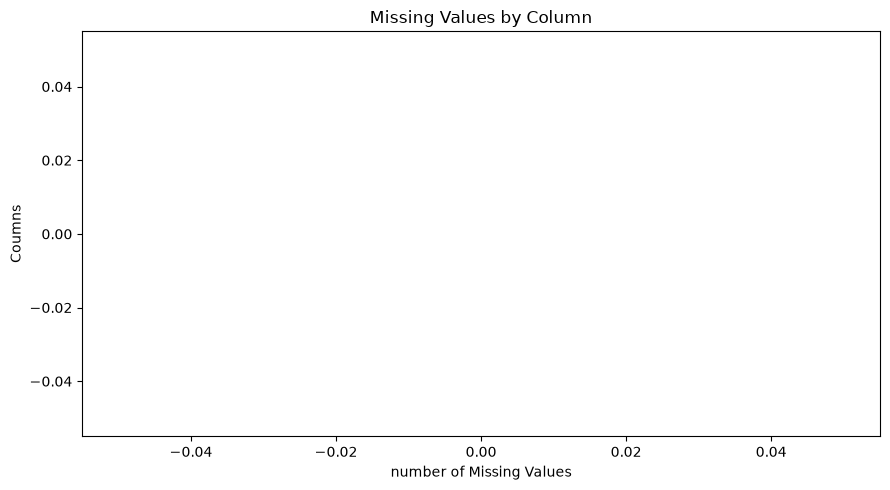

In [18]:
missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0 ]
plt.figure(figsize=(9,5))
plt.barh(
    missing_data.index,
    missing_data.values)
plt.title("Missing Values by Column")
plt.xlabel("number of Missing Values")
plt.ylabel("Coumns")
plt.tight_layout()

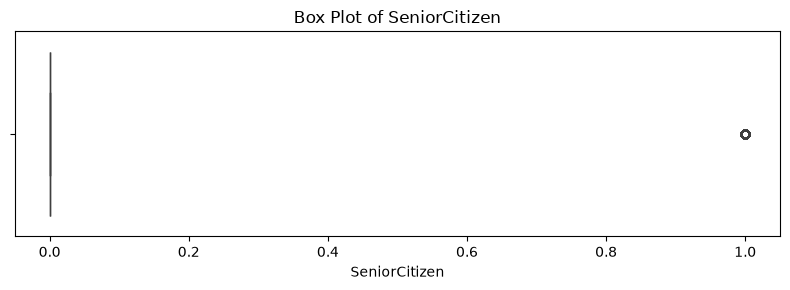

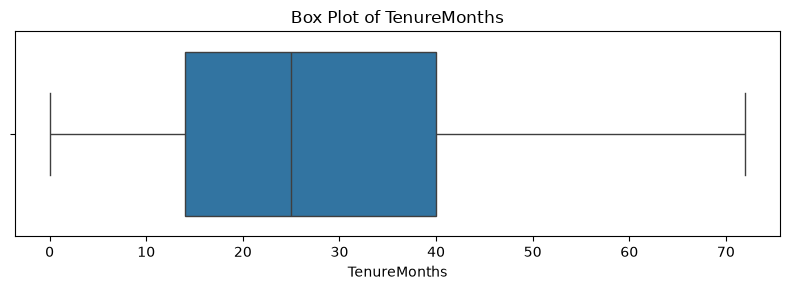

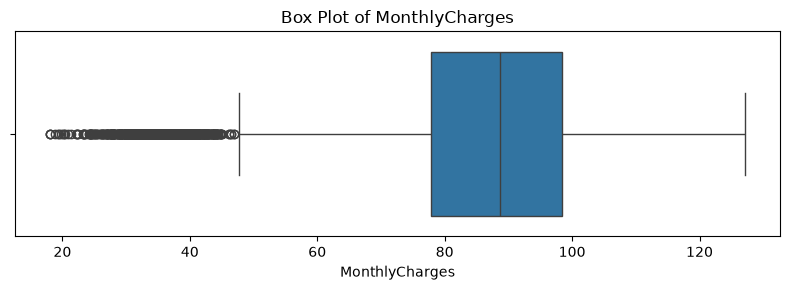

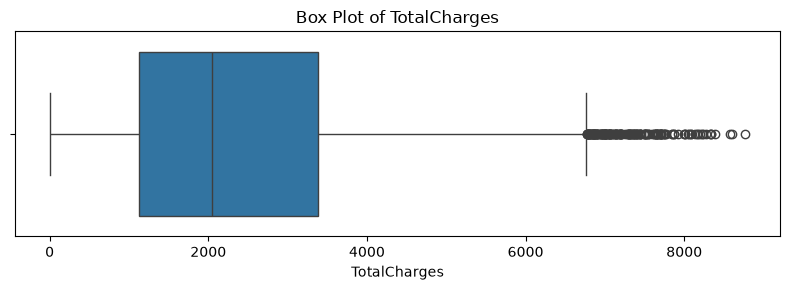

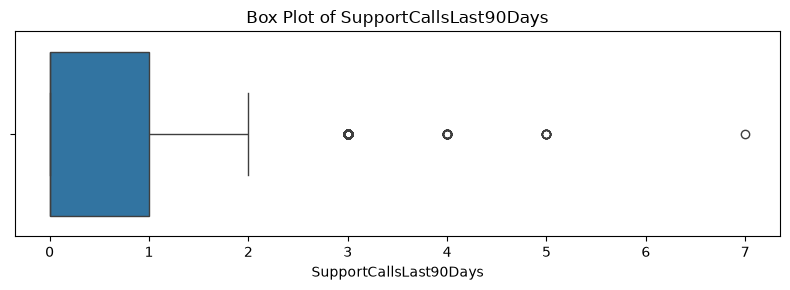

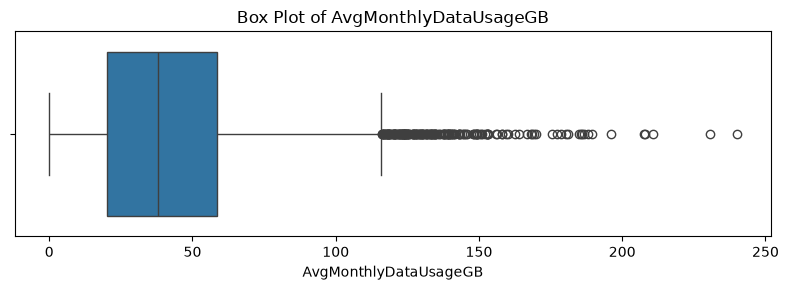

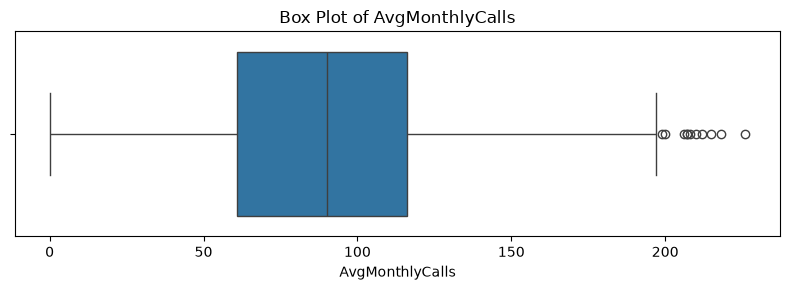

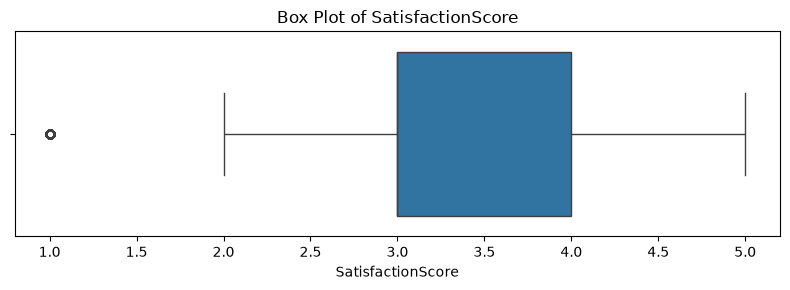

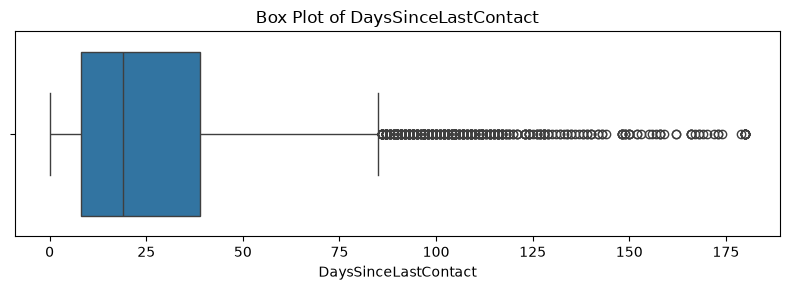

In [19]:
numerical_columns = df.select_dtypes(include="number").columns

for column in numerical_columns:
    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df[column])

    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

In [20]:
df_oringinal= df.copy()
original_row_count = len(df)
print("Originals Rows:",original_row_count)

Originals Rows: 8000


In [21]:
# Fill the categorical column with its mode
online_backup_mode = df["OnlineBackup"].mode()

if not online_backup_mode.empty:
    df["OnlineBackup"] = df["OnlineBackup"].fillna(
        online_backup_mode.iloc[0]
    )


# Fill numerical columns with their medians
numerical_columns = [
    "AvgMonthlyDataUsageGB",
    "SatisfactionScore",
    "DaysSinceLastContact"
]

for column in numerical_columns:
    median_value = df[column].median()

    df[column] = df[column].fillna(median_value)

    print(
        column,
        "median used:",
        median_value
    )

AvgMonthlyDataUsageGB median used: 37.8
SatisfactionScore median used: 3.0
DaysSinceLastContact median used: 19.0


In [22]:
print("Missing values after treatement:")
print(df.isnull().sum()[
    df.isnull().sum() > 0
    ])

Missing values after treatement:
Series([], dtype: int64)


In [23]:
duplicate_count = df . duplicated().sum()
print ("Duplicated Rows :", duplicate_count)

Duplicated Rows : 0


In [24]:
print(
    "Duplicate Customer IDs:",
    df["CustomerID"].duplicated().sum()
)

Duplicate Customer IDs: 0


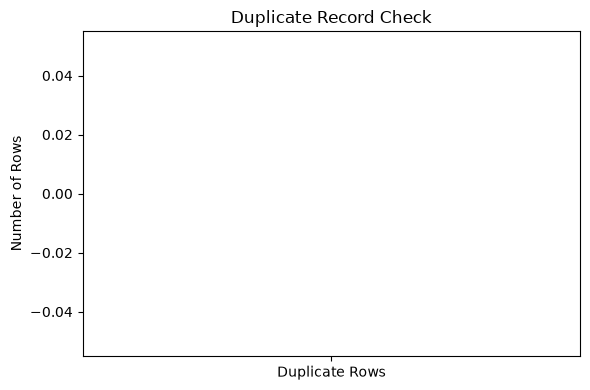

In [25]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Duplicate Rows"],
    [duplicate_count]
)

plt.title("Duplicate Record Check")
plt.ylabel("Number of Rows")

plt.tight_layout()
plt.show()

In [26]:
print(df.dtypes)

CustomerID                    str
Gender                        str
SeniorCitizen               int64
Partner                       str
Dependents                    str
TenureMonths                int64
PhoneService                  str
MultipleLines                 str
InternetService               str
OnlineSecurity                str
OnlineBackup                  str
DeviceProtection              str
TechSupport                   str
StreamingTV                   str
StreamingMovies               str
ContractType                  str
PaperlessBilling              str
PaymentMethod                 str
MonthlyCharges            float64
TotalCharges              float64
SupportCallsLast90Days      int64
ComplaintRaised               str
AvgMonthlyDataUsageGB     float64
AvgMonthlyCalls             int64
SatisfactionScore         float64
DaysSinceLastContact      float64
Churn                         str
dtype: object


In [27]:
numerical_columns = [
    "TenureMonths",
    "MonthlyCharges",
    "TotalCharges",
    "SupportCallsLast90Days",
    "AvgMonthlyDataUsageGB",
    "AvgMonthlyCalls",
    "SatisfactionScore",
    "DaysSinceLastContact"
]
for column in numerical_columns:
    if column in df.columns:
        print(
            column,
            "->",
            df[column].dtype
        )

TenureMonths -> int64
MonthlyCharges -> float64
TotalCharges -> float64
SupportCallsLast90Days -> int64
AvgMonthlyDataUsageGB -> float64
AvgMonthlyCalls -> int64
SatisfactionScore -> float64
DaysSinceLastContact -> float64


In [28]:
print(df[numerical_columns].describe().T)

                         count         mean          std   min        25%  \
TenureMonths            8000.0    28.976875    18.524855   0.0    14.0000   
MonthlyCharges          8000.0    84.789483    20.519515  18.0    77.8775   
TotalCharges            8000.0  2454.026473  1720.052730   0.0  1120.2675   
SupportCallsLast90Days  8000.0     0.624250     0.797741   0.0     0.0000   
AvgMonthlyDataUsageGB   8000.0    42.024913    30.695734   0.0    20.1000   
AvgMonthlyCalls         8000.0    86.398500    43.240423   0.0    61.0000   
SatisfactionScore       8000.0     3.427500     0.949793   1.0     3.0000   
DaysSinceLastContact    8000.0    27.834500    27.643695   0.0     8.0000   

                            50%      75%      max  
TenureMonths              25.00    40.00    72.00  
MonthlyCharges            88.70    98.42   127.17  
TotalCharges            2050.16  3380.95  8768.90  
SupportCallsLast90Days     0.00     1.00     7.00  
AvgMonthlyDataUsageGB     37.80    58.50   240

In [29]:
print(
    df["SeniorCitizen"].value_counts(dropna=False)
)

SeniorCitizen
0    6746
1    1254
Name: count, dtype: int64


In [30]:
categorical_columns = df.select_dtypes(
    include=["object", "string"]
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


CustomerID
CustomerID
CUST000001    1
CUST000002    1
CUST000003    1
CUST000004    1
CUST000005    1
             ..
CUST007996    1
CUST007997    1
CUST007998    1
CUST007999    1
CUST008000    1
Name: count, Length: 8000, dtype: int64

Gender
Gender
Male          3986
Female        3839
Non-binary     175
Name: count, dtype: int64

Partner
Partner
No     4307
Yes    3693
Name: count, dtype: int64

Dependents
Dependents
No     6166
Yes    1834
Name: count, dtype: int64

PhoneService
PhoneService
Yes    7278
No      722
Name: count, dtype: int64

MultipleLines
MultipleLines
Yes                 3949
No                  3329
No phone service     722
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3427
DSL            2459
5G Home        1299
No              815
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     4440
Yes                    2745
No internet service     815
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No       

In [31]:
for column in categorical_columns:
    df[column] = df[column].str.strip()
    print(df["ContractType"].value_counts())
print(df["Churn"].value_counts())

ContractType
Month-to-month    4441
One year          1944
Two year          1615
Name: count, dtype: int64
ContractType
Month-to-month    4441
One year          1944
Two year          1615
Name: count, dtype: int64
ContractType
Month-to-month    4441
One year          1944
Two year          1615
Name: count, dtype: int64
ContractType
Month-to-month    4441
One year          1944
Two year          1615
Name: count, dtype: int64
ContractType
Month-to-month    4441
One year          1944
Two year          1615
Name: count, dtype: int64
ContractType
Month-to-month    4441
One year          1944
Two year          1615
Name: count, dtype: int64
ContractType
Month-to-month    4441
One year          1944
Two year          1615
Name: count, dtype: int64
ContractType
Month-to-month    4441
One year          1944
Two year          1615
Name: count, dtype: int64
ContractType
Month-to-month    4441
One year          1944
Two year          1615
Name: count, dtype: int64
ContractType
Month-to-month 

C:\Users\Sakshi Mandvakar\AppData\Local\Temp\ipykernel_11080\1920004620.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[column].dropna(), vert=False)


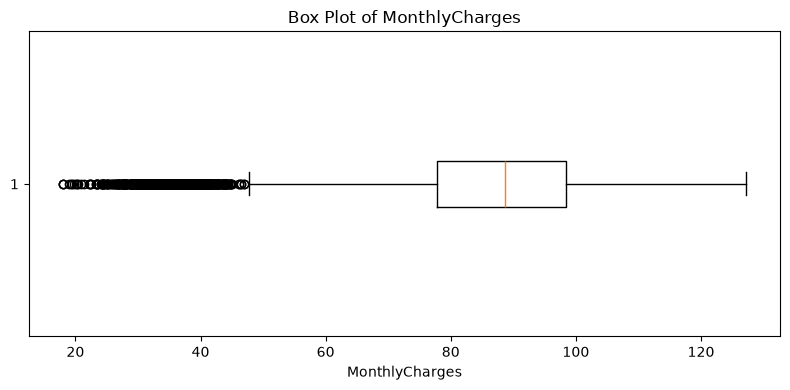

C:\Users\Sakshi Mandvakar\AppData\Local\Temp\ipykernel_11080\1920004620.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[column].dropna(), vert=False)


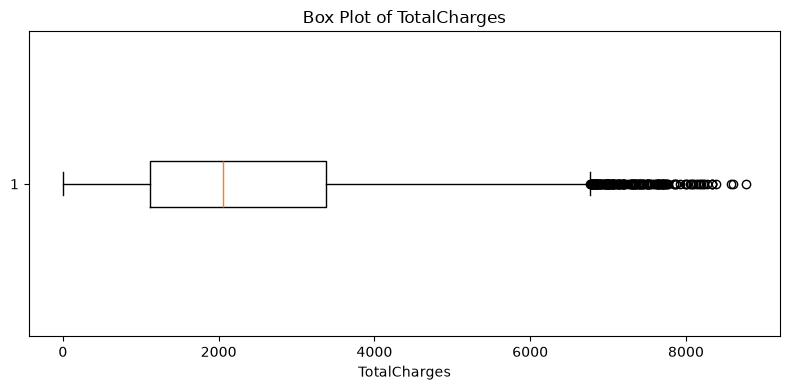

C:\Users\Sakshi Mandvakar\AppData\Local\Temp\ipykernel_11080\1920004620.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[column].dropna(), vert=False)


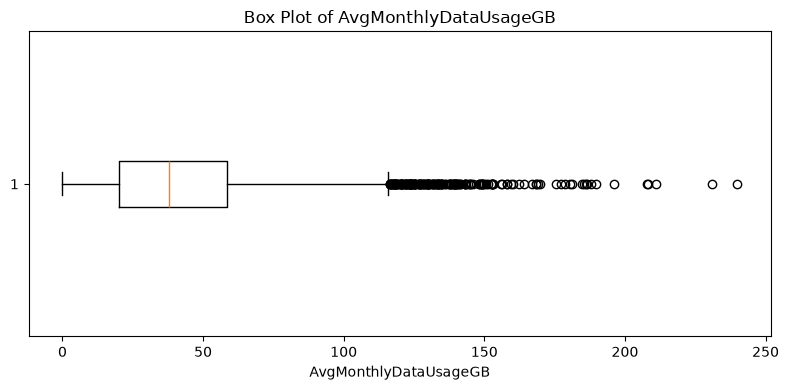

C:\Users\Sakshi Mandvakar\AppData\Local\Temp\ipykernel_11080\1920004620.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[column].dropna(), vert=False)


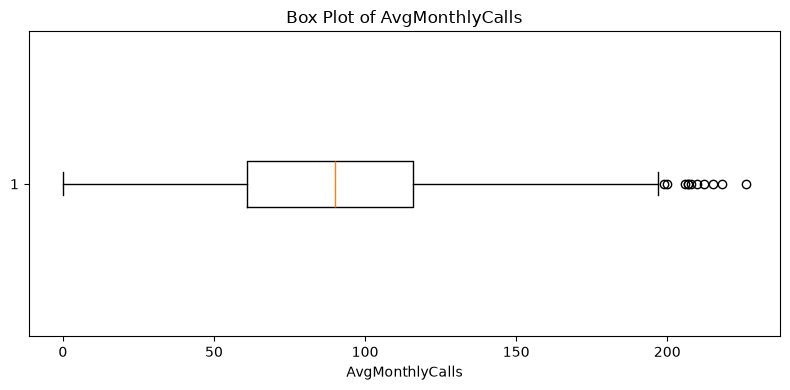

C:\Users\Sakshi Mandvakar\AppData\Local\Temp\ipykernel_11080\1920004620.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[column].dropna(), vert=False)


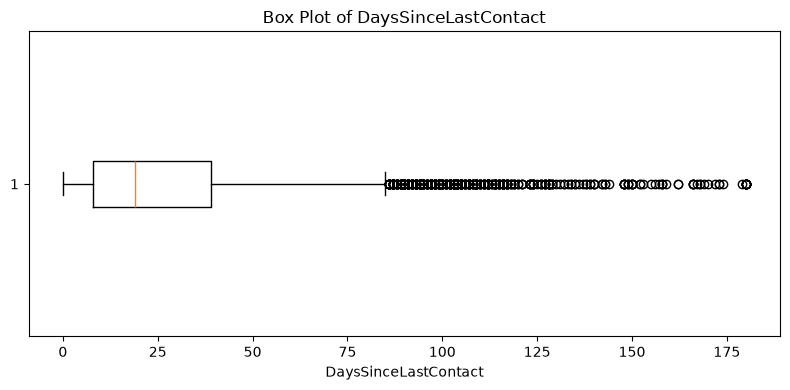

In [32]:
outlier_columns = [
    "MonthlyCharges",
    "TotalCharges",
    "AvgMonthlyDataUsageGB",
    "AvgMonthlyCalls",
    "DaysSinceLastContact"
]

for column in outlier_columns:

    plt.figure(figsize=(8, 4))

    plt.boxplot(df[column].dropna(), vert=False)

    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

In [33]:
def iqr_analysis(data, column):

    values = data[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = data[
        data[column].notna()
        & (
            (data[column] < lower_bound)
            | (data[column] > upper_bound)
        )
    ]
    print("\nColumn:", column)
    print("Q1:", round(q1, 2))
    print("Q3:", round(q3, 2))
    print("IQR:", round(iqr, 2))
    print("Lower Bound:", round(lower_bound, 2))
    print("Upper Bound:", round(upper_bound, 2))
    print("Potential Outliers:", len(outliers))

    return outliers


# Select numerical columns
outlier_columns = df.select_dtypes(include="number").columns

# Analyze outliers in each numerical column
for column in outlier_columns:
    potential_outliers = iqr_analysis(df, column)


Column: SeniorCitizen
Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Potential Outliers: 1254

Column: TenureMonths
Q1: 14.0
Q3: 40.0
IQR: 26.0
Lower Bound: -25.0
Upper Bound: 79.0
Potential Outliers: 0

Column: MonthlyCharges
Q1: 77.88
Q3: 98.42
IQR: 20.54
Lower Bound: 47.06
Upper Bound: 129.23
Potential Outliers: 812

Column: TotalCharges
Q1: 1120.27
Q3: 3380.95
IQR: 2260.68
Lower Bound: -2270.76
Upper Bound: 6771.97
Potential Outliers: 171

Column: SupportCallsLast90Days
Q1: 0.0
Q3: 1.0
IQR: 1.0
Lower Bound: -1.5
Upper Bound: 2.5
Potential Outliers: 206

Column: AvgMonthlyDataUsageGB
Q1: 20.1
Q3: 58.5
IQR: 38.4
Lower Bound: -37.5
Upper Bound: 116.1
Potential Outliers: 178

Column: AvgMonthlyCalls
Q1: 61.0
Q3: 116.0
IQR: 55.0
Lower Bound: -21.5
Upper Bound: 198.5
Potential Outliers: 11

Column: SatisfactionScore
Q1: 3.0
Q3: 4.0
IQR: 1.0
Lower Bound: 1.5
Upper Bound: 5.5
Potential Outliers: 156

Column: DaysSinceLastContact
Q1: 8.0
Q3: 39.0
IQR: 31.0
Lower Bound: -38.5
Up

In [34]:


df_original = pd.read_csv(
    "Customer_Churn_Prediction_8000_Records.csv"
)

print("Original dataset shape:", df_original.shape)

Original dataset shape: (8000, 27)


In [35]:
original_row_count = len(df_original)

In [36]:
final_row_count = len(df)

In [37]:
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Original Rows",
        "Original Columns",
        "Original Missing Values",
        "Original Duplicate Rows",
        "Final Rows",
        "Final Columns",
        "Final Missing Values",
        "Final Duplicate Rows"
    ],
    "Value": [
        len(df_original),
        df_original.shape[1],
        int(df_original.isnull().sum().sum()),
        int(df_original.duplicated().sum()),
        len(df),
        df.shape[1],
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum())
    ]
})

print(cleaning_summary)


                    Metric  Value
0            Original Rows   8000
1         Original Columns     27
2  Original Missing Values    464
3  Original Duplicate Rows      0
4               Final Rows   8000
5            Final Columns     27
6     Final Missing Values      0
7     Final Duplicate Rows      0


In [38]:
df.to_csv(
    "cleaned_customer_churn.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [39]:
print("Final Shape:", df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nRemaining Duplicate Rows:")
print(df.duplicated().sum())

Final Shape: (8000, 27)

Remaining Missing Values:
Series([], dtype: int64)

Remaining Duplicate Rows:
0


In [40]:
df.isnull().sum()

CustomerID                0
Gender                    0
SeniorCitizen             0
Partner                   0
Dependents                0
TenureMonths              0
PhoneService              0
MultipleLines             0
InternetService           0
OnlineSecurity            0
OnlineBackup              0
DeviceProtection          0
TechSupport               0
StreamingTV               0
StreamingMovies           0
ContractType              0
PaperlessBilling          0
PaymentMethod             0
MonthlyCharges            0
TotalCharges              0
SupportCallsLast90Days    0
ComplaintRaised           0
AvgMonthlyDataUsageGB     0
AvgMonthlyCalls           0
SatisfactionScore         0
DaysSinceLastContact      0
Churn                     0
dtype: int64

In [41]:
# Day39 -EDA (EXPLORAT DATA ANALYSIS)

churn_rate = df["Churn"].value_counts(normalize=True) * 100

print(churn_rate.round(2))

Churn
No     82.0
Yes    18.0
Name: proportion, dtype: float64


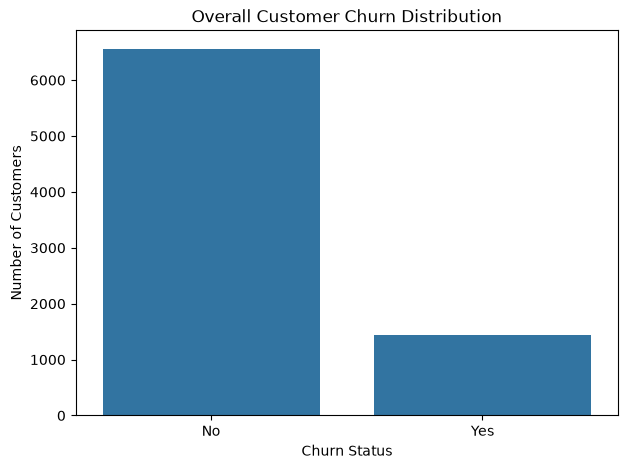

In [42]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Overall Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [43]:
df["TenureGroup"] = pd.cut(
    df["TenureMonths"],
    bins=[-1, 12, 36, float("inf")],
    labels=["New", "Medium", "Long-term"]
)

tenure_churn = df.groupby(
    "TenureGroup", observed=False
).agg(
    Customers=("Churn", "size"),
    Churned=("Churn", lambda x: (x == "Yes").sum())
)

tenure_churn["ChurnRate"] = (
    tenure_churn["Churned"] /
    tenure_churn["Customers"] * 100
)

print(tenure_churn.round(2))

             Customers  Churned  ChurnRate
TenureGroup                               
New               1603      434      27.07
Medium            4032      739      18.33
Long-term         2365      267      11.29


<Axes: xlabel='TenureGroup', ylabel='TenureMonths'>

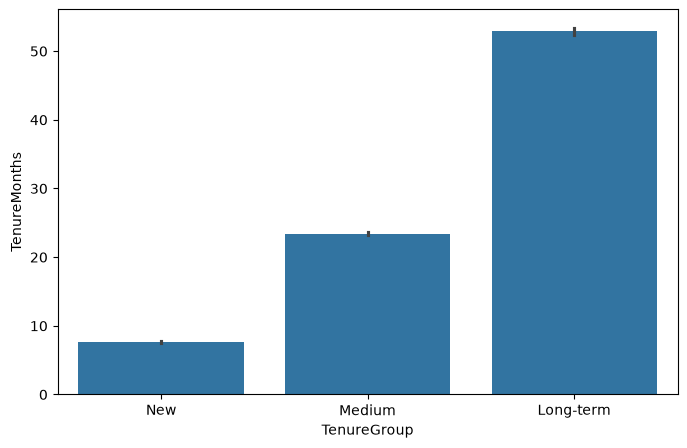

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="TenureGroup",
    y="ChurnFlag" if "ChurnFlag" in df.columns else "TenureMonths"
)

In [45]:
contract_churn = df.groupby("ContractType").agg(
    Customers=("Churn", "size"),
    Churned=("Churn", lambda x: (x == "Yes").sum())
)

contract_churn["ChurnRate"] = (
    contract_churn["Churned"] /
    contract_churn["Customers"] * 100
)

print(contract_churn.sort_values(
    "ChurnRate", ascending=False
).round(2))

                Customers  Churned  ChurnRate
ContractType                                 
Month-to-month       4441     1236      27.83
One year             1944      144       7.41
Two year             1615       60       3.72


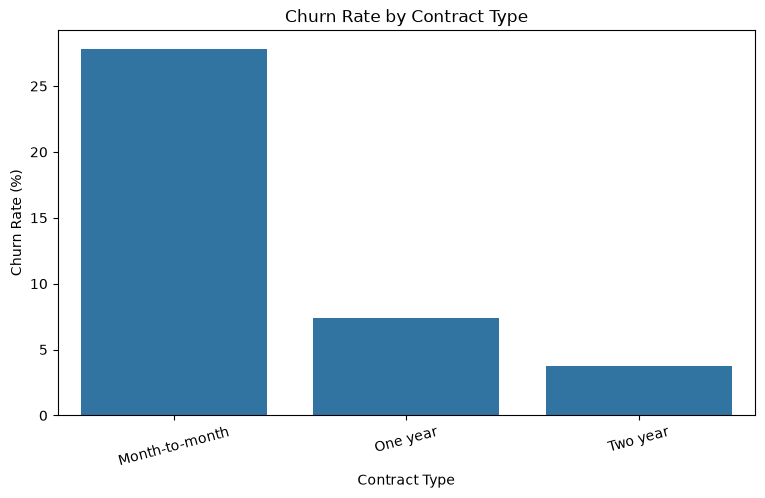

In [46]:
contract_plot = contract_churn.reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=contract_plot,
    x="ContractType",
    y="ChurnRate"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)


plt.show()

In [47]:
print(
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

       count   mean  median   min     max
Churn                                    
No      6560  84.07    88.2  18.0  127.17
Yes     1440  88.09    90.6  18.0  124.25


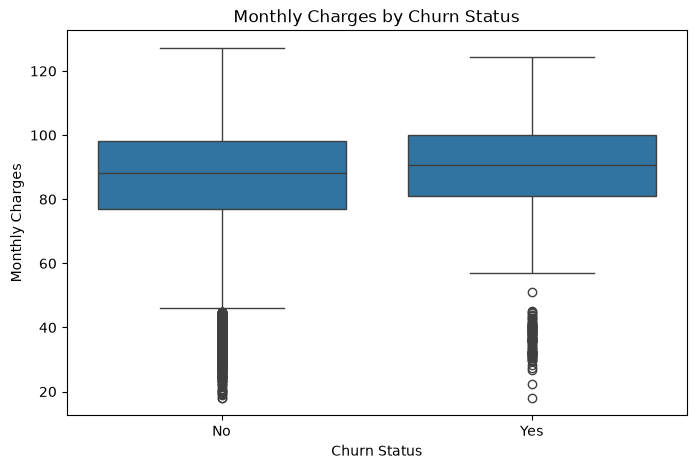

In [48]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")


plt.show()

In [49]:
payment_churn = df.groupby("PaymentMethod").agg(
    Customers=("Churn", "size"),
    Churned=("Churn", lambda x: (x == "Yes").sum())
)

payment_churn["ChurnRate"] = (
    payment_churn["Churned"] /
    payment_churn["Customers"] * 100
)

print(payment_churn.sort_values(
    "ChurnRate", ascending=False
).round(2))

                           Customers  Churned  ChurnRate
PaymentMethod                                           
Electronic check                2736      605      22.11
Credit card (automatic)         2134      354      16.59
Mailed check                    1130      182      16.11
Bank transfer (automatic)       2000      299      14.95


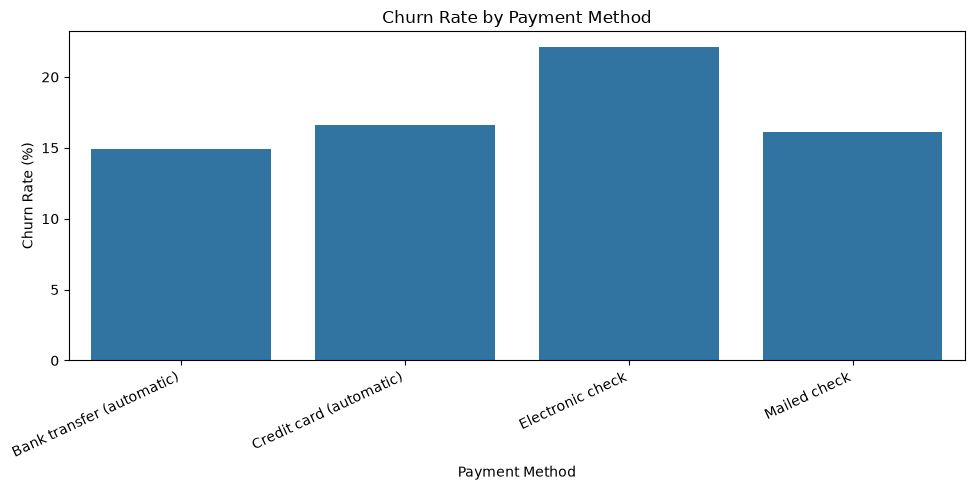

In [50]:
payment_plot = payment_churn.reset_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_plot,
    x="PaymentMethod" ,
    y="ChurnRate"
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [51]:
complaint_churn = df.groupby("ComplaintRaised").agg(
    Customers=("Churn", "size"),
    Churned=("Churn", lambda x: (x == "Yes").sum())
)

complaint_churn["ChurnRate"] = (
    complaint_churn["Churned"] /
    complaint_churn["Customers"] * 100
)

print(complaint_churn.round(2))

                 Customers  Churned  ChurnRate
ComplaintRaised                               
No                    7486     1186      15.84
Yes                    514      254      49.42


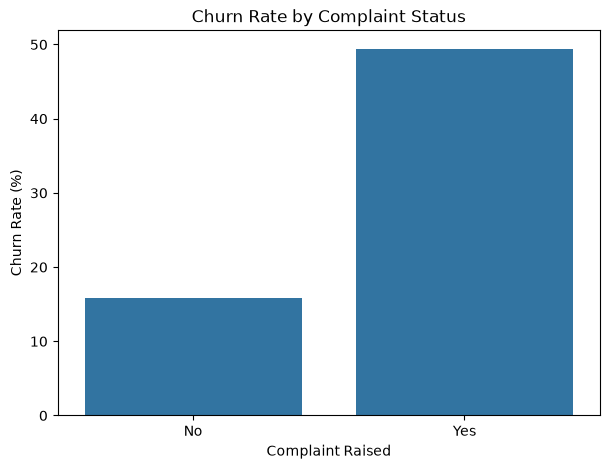

In [52]:
complaint_plot = complaint_churn.reset_index()

plt.figure(figsize=(7, 5))

sns.barplot(
    data=complaint_plot,
    x="ComplaintRaised",
    y="ChurnRate"
)

plt.title("Churn Rate by Complaint Status")
plt.xlabel("Complaint Raised")
plt.ylabel("Churn Rate (%)")
plt.show()

In [58]:
# Day40 - STATISTICAL ANALYSIS
from scipy import stats
num_cols = ["TenureMonths", "MonthlyCharges", "TotalCharges"]

print(df[num_cols].describe())

       TenureMonths  MonthlyCharges  TotalCharges
count   8000.000000     8000.000000   8000.000000
mean      28.976875       84.789483   2454.026473
std       18.524855       20.519515   1720.052730
min        0.000000       18.000000      0.000000
25%       14.000000       77.877500   1120.267500
50%       25.000000       88.700000   2050.160000
75%       40.000000       98.420000   3380.950000
max       72.000000      127.170000   8768.900000


In [54]:
print(df.columns.tolist())

['CustomerID', 'Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'TenureMonths', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'ContractType', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'SupportCallsLast90Days', 'ComplaintRaised', 'AvgMonthlyDataUsageGB', 'AvgMonthlyCalls', 'SatisfactionScore', 'DaysSinceLastContact', 'Churn', 'TenureGroup']


In [55]:
summary = df.groupby("Churn")[num_cols].describe().T
print(summary)

Churn                          No          Yes
TenureMonths   count  6560.000000  1440.000000
               mean     30.233384    23.252778
               std      18.694304    16.573378
               min       0.000000     0.000000
               25%      15.750000    11.000000
               50%      27.000000    19.000000
               75%      42.000000    31.000000
               max      72.000000    72.000000
MonthlyCharges count  6560.000000  1440.000000
               mean     84.065966    88.085500
               std      20.984729    17.890707
               min      18.000000    18.000000
               25%      76.890000    81.140000
               50%      88.205000    90.595000
               75%      98.052500   100.062500
               max     127.170000   124.250000
TotalCharges   count  6560.000000  1440.000000
               mean   2542.005723  2053.232111
               std    1738.848254  1571.075361
               min       0.000000     0.000000
             

In [59]:
numeric_cols = [
    "TenureMonths",
    "MonthlyCharges",
    "TotalCharges",
    "SupportCallsLast90Days",
    "AvgMonthlyDataUsageGB",
    "AvgMonthlyCalls",
    "SatisfactionScore",
    "DaysSinceLastContact"
]

group_summary = df.groupby("Churn")[numeric_cols].agg(
    ["mean", "median", "std", "min", "max"]
)

print(group_summary)

      TenureMonths                           MonthlyCharges          \
              mean median        std min max           mean  median   
Churn                                                                 
No       30.233384   27.0  18.694304   0  72      84.065966  88.205   
Yes      23.252778   19.0  16.573378   0  72      88.085500  90.595   

                                ... SatisfactionScore                        \
             std   min     max  ...              mean median       std  min   
Churn                           ...                                           
No     20.984729  18.0  127.17  ...          3.555030    4.0  0.908376  1.0   
Yes    17.890707  18.0  124.25  ...          2.846528    3.0  0.917395  1.0   

           DaysSinceLastContact                                
       max                 mean median        std  min    max  
Churn                                                          
No     5.0             27.86814   19.0  27.669000  0.0  

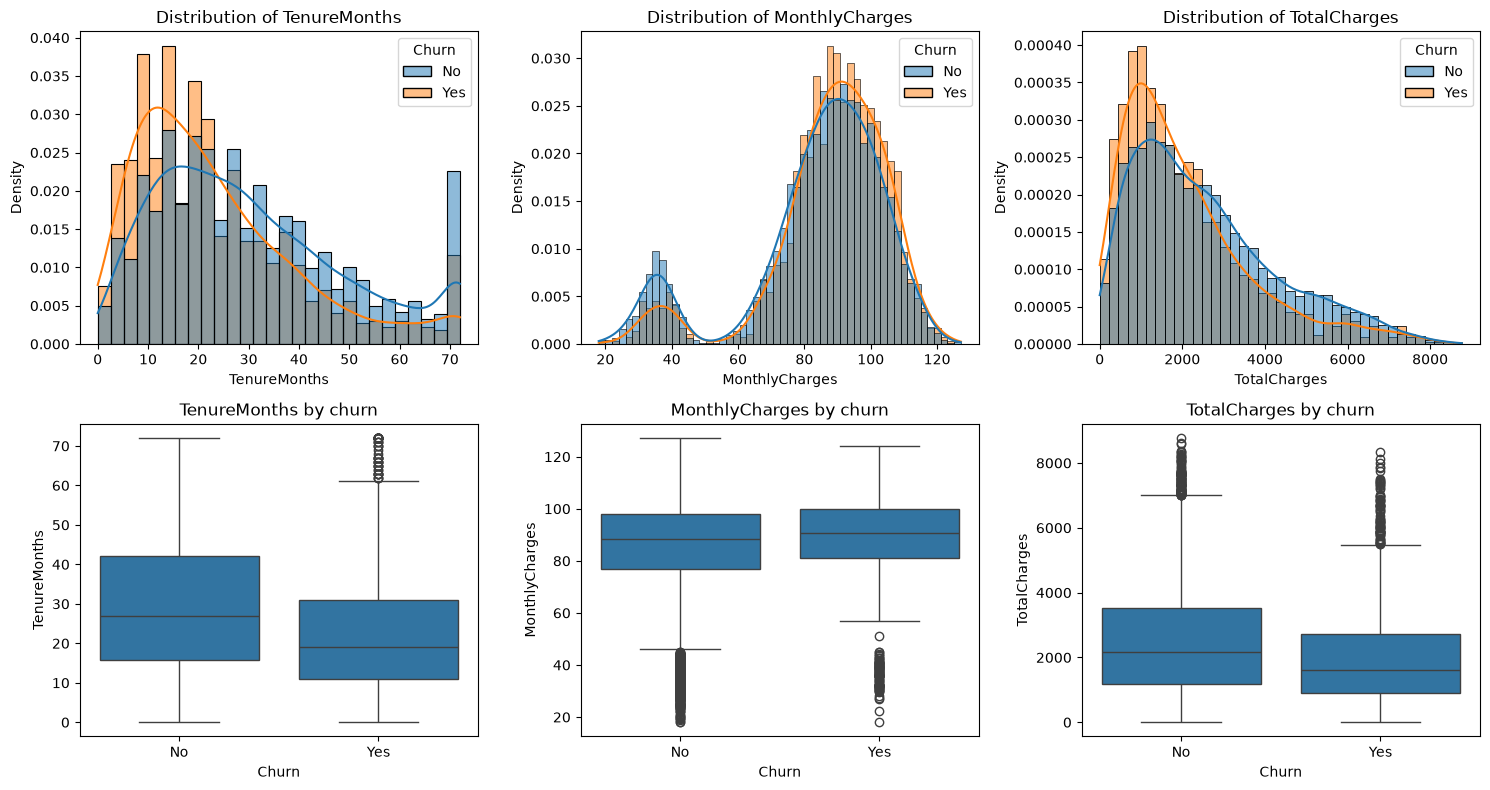

TenureMonths      0.756543
MonthlyCharges   -1.218049
TotalCharges      0.962133
dtype: float64


In [56]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, c in enumerate(num_cols):
    sns.histplot(data=df, x=c, hue="Churn", kde=True, stat="density", common_norm=False, ax=axes[0, i])
    axes[0, i].set_title(f"Distribution of {c}")
    sns.boxplot(data=df, x="Churn", y=c, ax=axes[1, i])
    axes[1, i].set_title(f"{c} by churn")
plt.tight_layout(); plt.show()
print(df[num_cols].skew())

In [61]:
# Task 2 Correlation
df["Churn_Binary"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})
numeric_df = df.select_dtypes(include="number").drop(
    columns=["SeniorCitizen"], errors="ignore"
)

correlation_matrix = numeric_df.corr()

print(correlation_matrix)

                        TenureMonths  MonthlyCharges  TotalCharges  \
TenureMonths                1.000000       -0.007766      0.911880   
MonthlyCharges             -0.007766        1.000000      0.340506   
TotalCharges                0.911880        0.340506      1.000000   
SupportCallsLast90Days     -0.020984        0.047950     -0.001910   
AvgMonthlyDataUsageGB      -0.004002        0.369045      0.124789   
AvgMonthlyCalls             0.010643        0.065757      0.033765   
SatisfactionScore           0.038497        0.027210      0.047930   
DaysSinceLastContact        0.003677        0.011681      0.002970   
Churn_Binary               -0.144780        0.075263     -0.109178   

                        SupportCallsLast90Days  AvgMonthlyDataUsageGB  \
TenureMonths                         -0.020984              -0.004002   
MonthlyCharges                        0.047950               0.369045   
TotalCharges                         -0.001910               0.124789   
Support

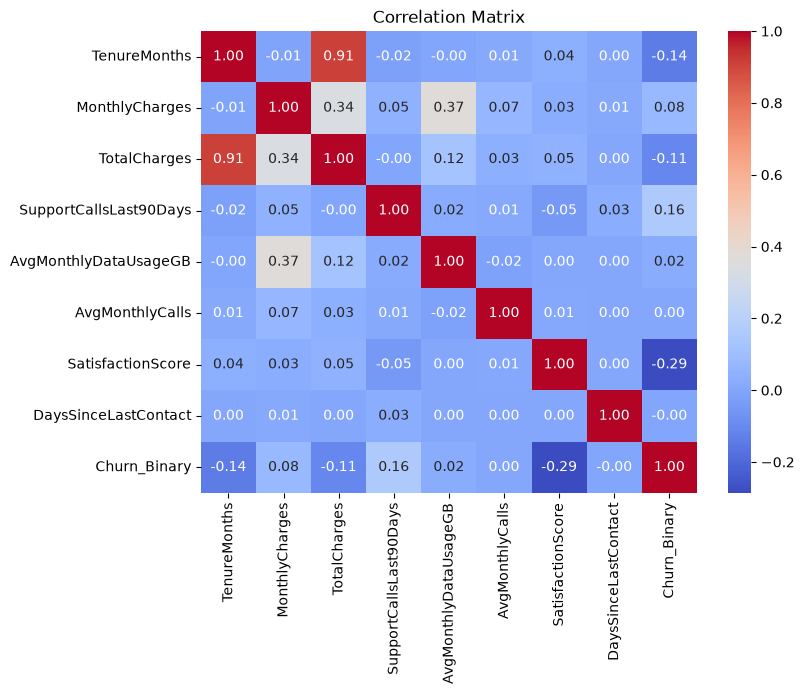

In [63]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [64]:
# Task 3 Compare groups
for c in num_cols:
    g = df.groupby("Churn")[c].agg(["count", "mean", "median", "std"])
    g["diff_mean(Yes-No)"] = g["mean"].diff()
    print(f"--- {c} ---"); print(g, "\n")

--- TenureMonths ---
       count       mean  median        std  diff_mean(Yes-No)
Churn                                                        
No      6560  30.233384    27.0  18.694304                NaN
Yes     1440  23.252778    19.0  16.573378          -6.980606 

--- MonthlyCharges ---
       count       mean  median        std  diff_mean(Yes-No)
Churn                                                        
No      6560  84.065966  88.205  20.984729                NaN
Yes     1440  88.085500  90.595  17.890707           4.019534 

--- TotalCharges ---
       count         mean    median          std  diff_mean(Yes-No)
Churn                                                              
No      6560  2542.005723  2164.575  1738.848254                NaN
Yes     1440  2053.232111  1622.435  1571.075361        -488.773611 



In [65]:
for c in ["ContractType", "InternetService", "PaymentMethod",
           "SeniorCitizen", "Gender"]:

    result = df.groupby(c)["Churn_Binary"].agg(["count", "mean"])

    result = result.rename(columns={"mean": "churn_rate"})
    result["churn_rate"] = result["churn_rate"] * 100

    print(f"\nChurn Analysis by {c}")
    print(result)


Churn Analysis by ContractType
                count  churn_rate
ContractType                     
Month-to-month   4441   27.831569
One year         1944    7.407407
Two year         1615    3.715170

Churn Analysis by InternetService
                 count  churn_rate
InternetService                   
5G Home           1299   15.550423
DSL               2459   16.144774
Fiber optic       3427   21.855851
No                 815   11.288344

Churn Analysis by PaymentMethod
                           count  churn_rate
PaymentMethod                               
Bank transfer (automatic)   2000   14.950000
Credit card (automatic)     2134   16.588566
Electronic check            2736   22.112573
Mailed check                1130   16.106195

Churn Analysis by SeniorCitizen
               count  churn_rate
SeniorCitizen                   
0               6746   17.388082
1               1254   21.291866

Churn Analysis by Gender
            count  churn_rate
Gender                       

In [66]:
numerical_columns = df.select_dtypes(include="number").columns

summary = df[numerical_columns].describe().T

summary["median"] = df[numerical_columns].median()
summary["std_deviation"] = df[numerical_columns].std()

summary = summary[
    ["count", "mean", "median", "std_deviation",
     "min", "25%", "50%", "75%", "max"]
]

display(summary.round(2))


,count,mean,median,std_deviation,min,25%,50%,75%,max
SeniorCitizen,8000.0,0.16,0.00,0.36,0.0,0.00,0.00,0.00,1.00
TenureMonths,8000.0,28.98,25.00,18.52,0.0,14.00,25.00,40.00,72.00
MonthlyCharges,8000.0,84.79,88.70,20.52,18.0,77.88,88.70,98.42,127.17
TotalCharges,8000.0,2454.03,2050.16,1720.05,0.0,1120.27,2050.16,3380.95,8768.90
SupportCallsLast90Days,8000.0,0.62,0.00,0.80,0.0,0.00,0.00,1.00,7.00
AvgMonthlyDataUsageGB,8000.0,42.02,37.80,30.70,0.0,20.10,37.80,58.50,240.00
AvgMonthlyCalls,8000.0,86.40,90.00,43.24,0.0,61.00,90.00,116.00,226.00
SatisfactionScore,8000.0,3.43,3.00,0.95,1.0,3.00,3.00,4.00,5.00
DaysSinceLastContact,8000.0,27.83,19.00,27.64,0.0,8.00,19.00,39.00,180.00
Churn_Binary,8000.0,0.18,0.00,0.38,0.0,0.00,0.00,0.00,1.00


In [67]:
group_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(group_summary.round(2))

       count   mean  median    std   min     max
Churn                                           
No      6560  84.07    88.2  20.98  18.0  127.17
Yes     1440  88.09    90.6  17.89  18.0  124.25


In [68]:
columns_to_compare = [
    "TenureMonths",
    "MonthlyCharges",
    "TotalCharges",
    "SupportCallsLast90Days",
    "AvgMonthlyDataUsageGB",
    "AvgMonthlyCalls",
    "SatisfactionScore",
    "DaysSinceLastContact"
]

for column in columns_to_compare:
    print(f"\nStatistics for {column}:")

    result = df.groupby("Churn")[column].agg(
        ["count", "mean", "median", "std"]
    )

    display(result.round(2))


Statistics for TenureMonths:


,count,mean,median,std
Churn,,,,
No,6560,30.23,27.0,18.69
Yes,1440,23.25,19.0,16.57



Statistics for MonthlyCharges:


,count,mean,median,std
Churn,,,,
No,6560,84.07,88.2,20.98
Yes,1440,88.09,90.6,17.89



Statistics for TotalCharges:


,count,mean,median,std
Churn,,,,
No,6560,2542.01,2164.57,1738.85
Yes,1440,2053.23,1622.44,1571.08


... (6 outputs left out)


Statistics for SatisfactionScore:


,count,mean,median,std
Churn,,,,
No,6560,3.56,4.0,0.91
Yes,1440,2.85,3.0,0.92



Statistics for DaysSinceLastContact:


,count,mean,median,std
Churn,,,,
No,6560,27.87,19.0,27.67
Yes,1440,27.68,19.0,27.54


In [69]:
df["Churn_Binary"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

numeric_df = df.select_dtypes(include="number")

# CustomerID is an identifier, so exclude it.
numeric_df = numeric_df.drop(
    columns=["CustomerID"],
    errors="ignore"
)

correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(2))

,SeniorCitizen,TenureMonths,MonthlyCharges,TotalCharges,SupportCallsLast90Days,AvgMonthlyDataUsageGB,AvgMonthlyCalls,SatisfactionScore,DaysSinceLastContact,Churn_Binary
SeniorCitizen,1.00,-0.01,0.00,-0.00,-0.00,-0.02,-0.00,-0.01,-0.00,0.04
TenureMonths,-0.01,1.00,-0.01,0.91,-0.02,-0.00,0.01,0.04,0.00,-0.14
MonthlyCharges,0.00,-0.01,1.00,0.34,0.05,0.37,0.07,0.03,0.01,0.08
TotalCharges,-0.00,0.91,0.34,1.00,-0.00,0.12,0.03,0.05,0.00,-0.11
SupportCallsLast90Days,-0.00,-0.02,0.05,-0.00,1.00,0.02,0.01,-0.05,0.03,0.16
AvgMonthlyDataUsageGB,-0.02,-0.00,0.37,0.12,0.02,1.00,-0.02,0.00,0.00,0.02
AvgMonthlyCalls,-0.00,0.01,0.07,0.03,0.01,-0.02,1.00,0.01,0.00,0.00
SatisfactionScore,-0.01,0.04,0.03,0.05,-0.05,0.00,0.01,1.00,0.00,-0.29
DaysSinceLastContact,-0.00,0.00,0.01,0.00,0.03,0.00,0.00,0.00,1.00,-0.00
Churn_Binary,0.04,-0.14,0.08,-0.11,0.16,0.02,0.00,-0.29,-0.00,1.00


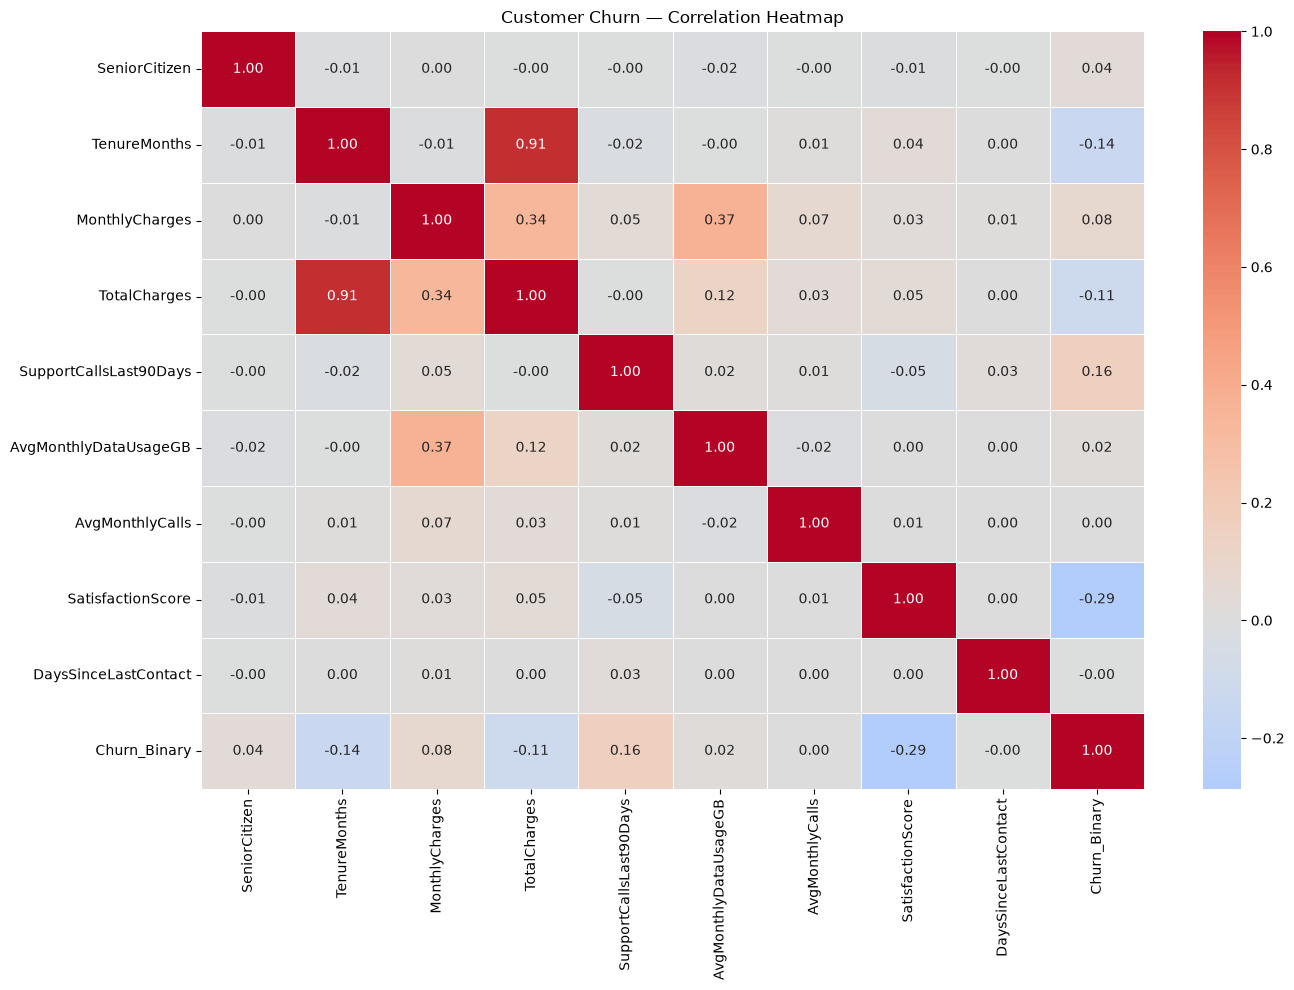

In [70]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Customer Churn — Correlation Heatmap")
plt.tight_layout()
plt.show()

In [71]:
contract_churn = pd.crosstab(
    df["ContractType"],
    df["Churn"],
    normalize="index"
) * 100

display(contract_churn.round(2))

Churn,No,Yes
ContractType,,
Month-to-month,72.17,27.83
One year,92.59,7.41
Two year,96.28,3.72


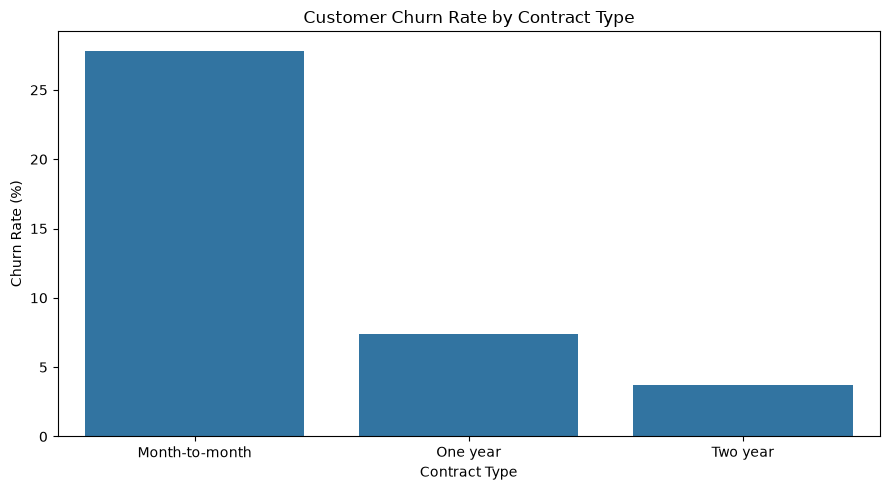

In [72]:
contract_rate = (
    df.assign(Churn_Flag=(df["Churn"] == "Yes").astype(int))
      .groupby("ContractType")["Churn_Flag"]
      .mean()
      .mul(100)
      .reset_index(name="ChurnRate")
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=contract_rate,
    x="ContractType",
    y="ChurnRate"
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

In [73]:
# Day 41 Feature Engineering
print(df.isnull().sum())

CustomerID                0
Gender                    0
SeniorCitizen             0
Partner                   0
Dependents                0
TenureMonths              0
PhoneService              0
MultipleLines             0
InternetService           0
OnlineSecurity            0
OnlineBackup              0
DeviceProtection          0
TechSupport               0
StreamingTV               0
StreamingMovies           0
ContractType              0
PaperlessBilling          0
PaymentMethod             0
MonthlyCharges            0
TotalCharges              0
SupportCallsLast90Days    0
ComplaintRaised           0
AvgMonthlyDataUsageGB     0
AvgMonthlyCalls           0
SatisfactionScore         0
DaysSinceLastContact      0
Churn                     0
TenureGroup               0
Churn_Binary              0
dtype: int64


In [74]:
print(df.columns.tolist())

['CustomerID', 'Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'TenureMonths', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'ContractType', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'SupportCallsLast90Days', 'ComplaintRaised', 'AvgMonthlyDataUsageGB', 'AvgMonthlyCalls', 'SatisfactionScore', 'DaysSinceLastContact', 'Churn', 'TenureGroup', 'Churn_Binary']


In [75]:
df["Tenure_Group"] = pd.cut(
    df["TenureMonths"],
    bins=[-1, 12, 36, float("inf")],
    labels=["New", "Medium", "Long-term"]
)

print(df[["TenureMonths", "Tenure_Group"]].head(10))

   TenureMonths Tenure_Group
0             4          New
1            35       Medium
2            51    Long-term
3            42    Long-term
4            30       Medium
5            16       Medium
6            16       Medium
7            43    Long-term
8            72    Long-term
9            45    Long-term


In [76]:
print(df["Tenure_Group"].value_counts())

Tenure_Group
Medium       4032
Long-term    2365
New          1603
Name: count, dtype: int64


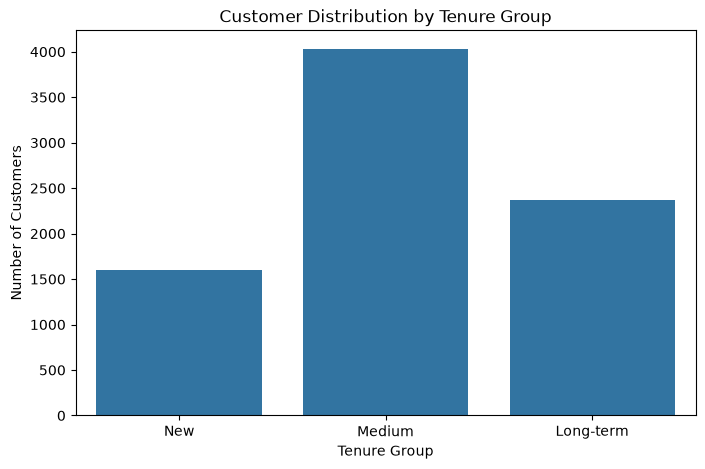

In [83]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Tenure_Group"
)

plt.title("Customer Distribution by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Number of Customers")
plt.show()

In [84]:
low_limit = df["MonthlyCharges"].median()
high_limit = df["MonthlyCharges"].quantile(0.75)

print("Low spending limit:", low_limit)
print("High spending limit:", high_limit)

Low spending limit: 88.7
High spending limit: 98.42


In [77]:
# Create Spending Categories
df["Spending_Category"] = pd.cut(
    df["MonthlyCharges"],
    bins=[-float("inf"), 70, 100, float("inf")],
    labels=["Low Spending", "Medium Spending", "High Spending"],
    right=False
)

print(df[["MonthlyCharges", "Spending_Category"]].head(10))

   MonthlyCharges Spending_Category
0           94.35   Medium Spending
1           92.29   Medium Spending
2           82.09   Medium Spending
3          107.06     High Spending
4          100.78     High Spending
5           89.97   Medium Spending
6           87.53   Medium Spending
7           29.05      Low Spending
8           47.00      Low Spending
9           28.07      Low Spending


In [86]:
df["Spending_Category"] = np.select(
    [
        df["MonthlyCharges"] <= low_limit,
        df["MonthlyCharges"] <= high_limit
    ],
    [
        "Low Spending",
        "Medium Spending"
    ],
    default="High Spending"
)
print(df[[
    "MonthlyCharges",
    "Spending_Category"
]].head(10))

   MonthlyCharges Spending_Category
0           94.35   Medium Spending
1           92.29   Medium Spending
2           82.09      Low Spending
3          107.06     High Spending
4          100.78     High Spending
5           89.97   Medium Spending
6           87.53      Low Spending
7           29.05      Low Spending
8           47.00      Low Spending
9           28.07      Low Spending


In [78]:
print(df["Spending_Category"].value_counts())

Spending_Category
Medium Spending    5082
High Spending      1707
Low Spending       1211
Name: count, dtype: int64


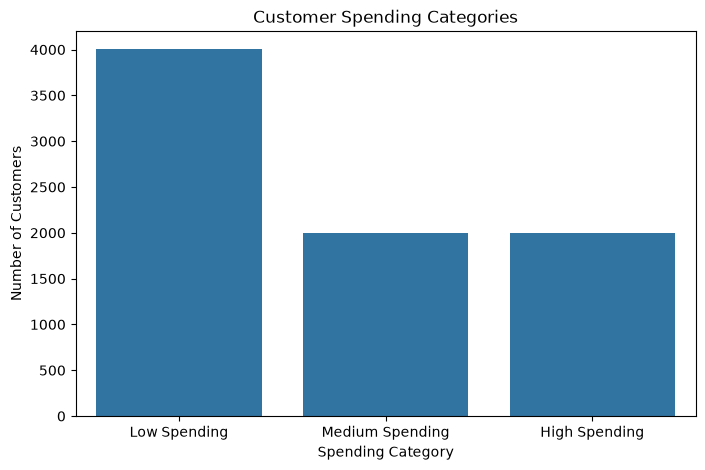

In [87]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Spending_Category",
    order=["Low Spending", "Medium Spending", "High Spending"]
)

plt.title("Customer Spending Categories")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")
plt.show()

In [79]:
churn_by_spending = df.groupby(
    "Spending_Category",
    observed=True
)["Churn"].value_counts(normalize=True).unstack(fill_value=0) * 100

print(churn_by_spending.round(2))

Churn                 No    Yes
Spending_Category              
Low Spending       88.11  11.89
Medium Spending    81.60  18.40
High Spending      78.85  21.15


In [88]:
# Create Usage Features
usage_cols = [
    "AvgMonthlyDataUsageGB",
    "AvgMonthlyCalls"
]

print(df[usage_cols].describe())



       AvgMonthlyDataUsageGB  AvgMonthlyCalls
count            8000.000000      8000.000000
mean               42.024913        86.398500
std                30.695734        43.240423
min                 0.000000         0.000000
25%                20.100000        61.000000
50%                37.800000        90.000000
75%                58.500000       116.000000
max               240.000000       226.000000


In [90]:
usage_median = df["AvgMonthlyDataUsageGB"].median()

df["Usage_Category"] = np.where(
    df["AvgMonthlyDataUsageGB"] <= usage_median,
    "Low Usage",
    "High Usage"
)

calls_median = df["AvgMonthlyCalls"].median()

df["Call_Usage_Category"] = np.where(
    df["AvgMonthlyCalls"] <= calls_median,
    "Low Calls",
    "High Calls"
)
print(df[[
    "AvgMonthlyDataUsageGB",
    "Usage_Category",
    "AvgMonthlyCalls",
    "Call_Usage_Category"
]].head(10))

   AvgMonthlyDataUsageGB Usage_Category  AvgMonthlyCalls Call_Usage_Category
0                  105.3     High Usage              121          High Calls
1                   23.0      Low Usage              115          High Calls
2                   53.6     High Usage              156          High Calls
3                  114.9     High Usage               78           Low Calls
4                   61.7     High Usage               65           Low Calls
5                   14.1      Low Usage              144          High Calls
6                   83.0     High Usage              101          High Calls
7                    0.0      Low Usage               30           Low Calls
8                    0.0      Low Usage               80           Low Calls
9                    0.0      Low Usage               83           Low Calls


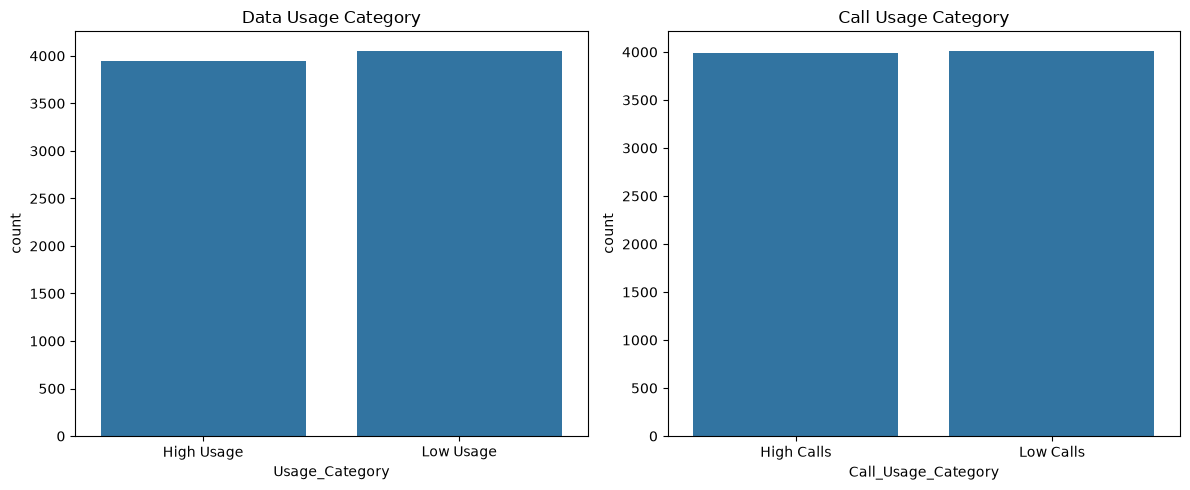

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    data=df,
    x="Usage_Category",
    ax=axes[0]
)

axes[0].set_title("Data Usage Category")

sns.countplot(
    data=df,
    x="Call_Usage_Category",
    ax=axes[1]
)

axes[1].set_title("Call Usage Category")

plt.tight_layout()
plt.show()

In [81]:
df["Average_Usage"] = df["AvgMonthlyDataUsageGB"]

print(df[["AvgMonthlyDataUsageGB", "Average_Usage"]].head(10))

   AvgMonthlyDataUsageGB  Average_Usage
0                  105.3          105.3
1                   23.0           23.0
2                   53.6           53.6
3                  114.9          114.9
4                   61.7           61.7
5                   14.1           14.1
6                   83.0           83.0
7                    0.0            0.0
8                    0.0            0.0
9                    0.0            0.0


In [93]:
# Task 5
median_data = df["AvgMonthlyDataUsageGB"].median()
median_calls = df["AvgMonthlyCalls"].median()

print("Median Data Usage:", median_data)
print("Median Monthly Calls:", median_calls)

Median Data Usage: 37.8
Median Monthly Calls: 90.0


In [94]:
df["Engagement_Score"] = (
    (df["AvgMonthlyDataUsageGB"] >= median_data).astype(int)
    + (df["AvgMonthlyCalls"] >= median_calls).astype(int)
)

# Handle missing usage measurements
missing_usage = (
    df["AvgMonthlyDataUsageGB"].isna()
    | df["AvgMonthlyCalls"].isna()
)

df.loc[missing_usage, "Engagement_Score"] = float("nan")

# Display results
print(df[[
    "AvgMonthlyDataUsageGB",
    "AvgMonthlyCalls",
    "Engagement_Score"
]].head(10))

   AvgMonthlyDataUsageGB  AvgMonthlyCalls  Engagement_Score
0                  105.3              121               2.0
1                   23.0              115               1.0
2                   53.6              156               2.0
3                  114.9               78               1.0
4                   61.7               65               1.0
5                   14.1              144               1.0
6                   83.0              101               2.0
7                    0.0               30               0.0
8                    0.0               80               0.0
9                    0.0               83               0.0


In [95]:
# DAY 42 — Encoding and Scaling
df_model = df.drop(columns=["CustomerID"], errors="ignore").copy()

In [96]:
X = df_model.drop(columns=["Churn"])
y = df_model["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nChurn values:")
print(y.value_counts())
y = y.map({"No": 0, "Yes": 1})

print(y.value_counts())
print("Missing target values:", y.isna().sum())

Features shape: (8000, 33)
Target shape: (8000,)

Churn values:
Churn
No     6560
Yes    1440
Name: count, dtype: int64
Churn
0    6560
1    1440
Name: count, dtype: int64
Missing target values: 0


In [97]:
# Numerical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Treat SeniorCitizen as categorical
if "SeniorCitizen" in numeric_features:
    numeric_features.remove("SeniorCitizen")

# Categorical columns, including SeniorCitizen
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

if "SeniorCitizen" in X.columns:
    categorical_features.append("SeniorCitizen")

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['TenureMonths', 'MonthlyCharges', 'TotalCharges', 'SupportCallsLast90Days', 'AvgMonthlyDataUsageGB', 'AvgMonthlyCalls', 'SatisfactionScore', 'DaysSinceLastContact', 'Churn_Binary', 'Average_Usage', 'Engagement_Score']

Categorical Features:
['Gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'ContractType', 'PaperlessBilling', 'PaymentMethod', 'ComplaintRaised', 'TenureGroup', 'Tenure_Group', 'Spending_Category', 'Usage_Category', 'Call_Usage_Category', 'SeniorCitizen']


C:\Users\Sakshi Mandvakar\AppData\Local\Temp\ipykernel_11080\431363856.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [98]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [99]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [100]:
import sklearn

print("Scikit-learn Version:", sklearn.__version__)

Scikit-learn Version: 1.9.1


In [101]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("All libraries imported successfully!")

All libraries imported successfully!


In [102]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [103]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (8000, 34)
Target Shape: (8000,)


In [104]:
print(X.columns.tolist())

['CustomerID', 'Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'TenureMonths', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'ContractType', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'SupportCallsLast90Days', 'ComplaintRaised', 'AvgMonthlyDataUsageGB', 'AvgMonthlyCalls', 'SatisfactionScore', 'DaysSinceLastContact', 'TenureGroup', 'Churn_Binary', 'Tenure_Group', 'Spending_Category', 'Average_Usage', 'Usage_Category', 'Call_Usage_Category', 'Engagement_Score']


In [105]:
# Task 4 Convert target into binary format
y = y.astype(str).str.strip().str.lower()

y = y.map({
    "yes": 1,
    "no": 0
})

print(y.value_counts())

Churn
0    6560
1    1440
Name: count, dtype: int64


In [106]:
print(y.dtype)
print(y.isnull().sum())

int64
0


In [107]:
# Task 5 Identify Numerical and Categorical features
numeric_features = X.select_dtypes(
    include=["number"]
).columns


categorical_features = X.select_dtypes(
    include=["object", "str", "category", "bool", "string"]
).columns

print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['SeniorCitizen', 'TenureMonths', 'MonthlyCharges', 'TotalCharges', 'SupportCallsLast90Days', 'AvgMonthlyDataUsageGB', 'AvgMonthlyCalls', 'SatisfactionScore', 'DaysSinceLastContact', 'Churn_Binary', 'Average_Usage', 'Engagement_Score']

Categorical Features:
['CustomerID', 'Gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'ContractType', 'PaperlessBilling', 'PaymentMethod', 'ComplaintRaised', 'TenureGroup', 'Tenure_Group', 'Spending_Category', 'Usage_Category', 'Call_Usage_Category']


In [108]:
# Task 6 Split Training and Testing Data 
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (6400, 34)
X_test: (1600, 34)
y_train: (6400,)
y_test: (1600,)


In [109]:
# Task 7 Apply one encoding
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(
    X_train[categorical_features]
)

X_test_encoded = encoder.transform(
    X_test[categorical_features]
)

print("Encoded Training Shape:", X_train_encoded.shape)
print("Encoded Testing Shape:", X_test_encoded.shape)

Encoded Training Shape: (6400, 6458)
Encoded Testing Shape: (1600, 6458)


In [110]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train[numeric_features]
)

X_test_scaled = scaler.transform(
    X_test[numeric_features]
)

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Scaled Training Shape: (6400, 12)
Scaled Testing Shape: (1600, 12)


In [111]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)
print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (6400, 6470)
Testing Shape: (1600, 6470)


In [112]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (6400, 6470)
Testing Shape: (1600, 6470)


In [113]:
feature_names = preprocessor.get_feature_names_out()

print("Total Features:", len(feature_names))
print(feature_names)

Total Features: 6470
['num__SeniorCitizen' 'num__TenureMonths' 'num__MonthlyCharges' ...
 'cat__Usage_Category_Low Usage' 'cat__Call_Usage_Category_High Calls'
 'cat__Call_Usage_Category_Low Calls']


In [114]:
# Day 43 - Train - Test Split
print(df["Churn"].value_counts())

print("\nMissing Values:")
print(df["Churn"].isnull().sum())

Churn
No     6560
Yes    1440
Name: count, dtype: int64

Missing Values:
0


In [115]:
X = df.drop("Churn", axis=1)

y = df["Churn"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (8000, 34)
y Shape: (8000,)


In [116]:
y = y.map({
    "No": 0,
    "Yes": 1
})

print(y.value_counts())

Churn
0    6560
1    1440
Name: count, dtype: int64


In [117]:
valid_rows = y.notna()

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

y = y.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Original Dataset:", X.shape)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Original Dataset: (8000, 34)
Training Features: (6400, 34)
Testing Features: (1600, 34)
Training Target: (6400,)
Testing Target: (1600,)


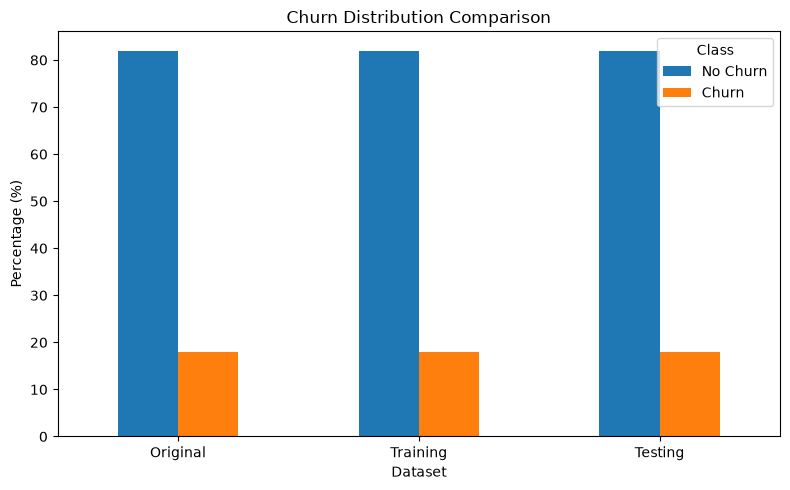

In [118]:
import matplotlib.pyplot as plt

distribution = pd.DataFrame({
    "Original": y.value_counts(normalize=True) * 100,
    "Training": y_train.value_counts(normalize=True) * 100,
    "Testing": y_test.value_counts(normalize=True) * 100
}).T

distribution = distribution.rename(
    columns={0: "No Churn", 1: "Churn"}
)

distribution.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Distribution Comparison")
plt.ylabel("Percentage (%)")
plt.xlabel("Dataset")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.tight_layout()
plt.show()

In [119]:

# DAY 43 — TRAIN-TEST SPLIT

In [120]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (8000, 35)

Columns:
['CustomerID', 'Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'TenureMonths', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'ContractType', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'SupportCallsLast90Days', 'ComplaintRaised', 'AvgMonthlyDataUsageGB', 'AvgMonthlyCalls', 'SatisfactionScore', 'DaysSinceLastContact', 'Churn', 'TenureGroup', 'Churn_Binary', 'Tenure_Group', 'Spending_Category', 'Average_Usage', 'Usage_Category', 'Call_Usage_Category', 'Engagement_Score']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 35 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   CustomerID              8000 non-null   str     
 1   Gender                  8000 non-null   str     
 2   SeniorCitiz

In [121]:
X = df.drop(columns=["Churn", "CustomerID"], errors="ignore")

y = df["Churn"]
print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nTarget Values:")
print(y.value_counts())

Features Shape: (8000, 33)
Target Shape: (8000,)

Target Values:
Churn
No     6560
Yes    1440
Name: count, dtype: int64


In [122]:
from sklearn.model_selection import train_test_split


In [123]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (6400, 33)
X_test: (1600, 33)
y_train: (6400,)
y_test: (1600,)


In [124]:
print("Original Dataset Churn Percentage:")
print(y.value_counts(normalize=True) * 100)

print("\nTraining Dataset Churn Percentage:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Dataset Churn Percentage:")
print(y_test.value_counts(normalize=True) * 100)

Original Dataset Churn Percentage:
Churn
No     82.0
Yes    18.0
Name: proportion, dtype: float64

Training Dataset Churn Percentage:
Churn
No     82.0
Yes    18.0
Name: proportion, dtype: float64

Testing Dataset Churn Percentage:
Churn
No     82.0
Yes    18.0
Name: proportion, dtype: float64


In [125]:
split_summary = pd.DataFrame({
    "Dataset": ["Original", "Training", "Testing"],
    "Total_Records": [
        len(y),
        len(y_train),
        len(y_test)
    ],
    "Churn_Percentage": [
        (y == "Yes").mean() * 100,
        (y_train == "Yes").mean() * 100,
        (y_test == "Yes").mean() * 100
    ]
})

split_summary

,Dataset,Total_Records,Churn_Percentage
0,Original,8000,18.0
1,Training,6400,18.0
2,Testing,1600,18.0


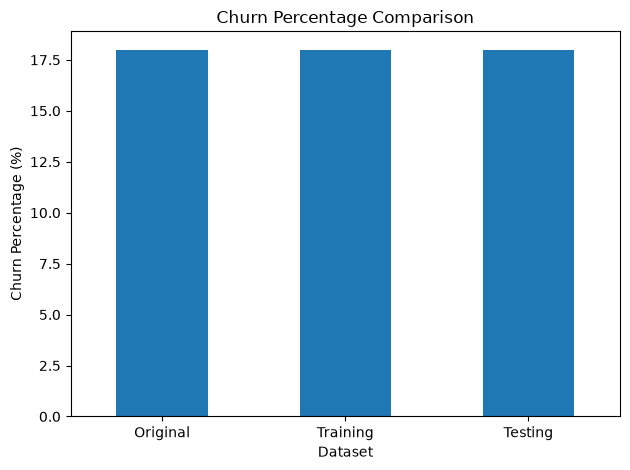

In [126]:
import matplotlib.pyplot as plt

split_summary.plot(
    x="Dataset",
    y="Churn_Percentage",
    kind="bar",
    legend=False
)

plt.title("Churn Percentage Comparison")
plt.ylabel("Churn Percentage (%)")
plt.xlabel("Dataset")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [127]:
split_summary.to_csv(
    "split_summary.csv",
    index=False
)

In [128]:
# Day 44 -Logistic Regression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression

In [129]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['SeniorCitizen', 'TenureMonths', 'MonthlyCharges', 'TotalCharges', 'SupportCallsLast90Days', 'AvgMonthlyDataUsageGB', 'AvgMonthlyCalls', 'SatisfactionScore', 'DaysSinceLastContact', 'Churn_Binary', 'Average_Usage', 'Engagement_Score']

Categorical Features: ['Gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'ContractType', 'PaperlessBilling', 'PaymentMethod', 'ComplaintRaised', 'TenureGroup', 'Tenure_Group', 'Spending_Category', 'Usage_Category', 'Call_Usage_Category']


In [130]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [131]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [132]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [133]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](33,)","['Gender','SeniorCitizen','Partner',...,'Usage_Category', 'Call_Usage_Category','Engagement_Score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,33
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spe

In [134]:
y_pred = model.predict(X_test)

print("Predicted Values:")
print(y_pred[:10])

Predicted Values:
['Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']


In [135]:
y_prob = model.predict_proba(X_test)[:, 1]

print("Predicted Probabilities:")
print(y_prob[:10])

Predicted Probabilities:
[9.98981318e-01 9.40284467e-04 4.39233158e-04 3.33772845e-04
 2.20910504e-04 7.02082192e-04 3.08483062e-04 6.64624032e-04
 9.98365560e-01 8.72404767e-04]


In [136]:
print(model.classes_)

['No' 'Yes']


In [137]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 1.0
Accuracy Percentage: 100.0


In [138]:
from sklearn.metrics import precision_score

precision = precision_score(
    y_test,
    y_pred,
    pos_label="Yes"
)

print("Precision:", precision)
print("Precision Percentage:", precision * 100)

Precision: 1.0
Precision Percentage: 100.0


In [139]:
from sklearn.metrics import recall_score

recall = recall_score(
    y_test,
    y_pred,
    pos_label="Yes"
)

print("Recall:", recall)
print("Recall Percentage:", recall * 100)

Recall: 1.0
Recall Percentage: 100.0


In [140]:
from sklearn.metrics import f1_score

f1 = f1_score(
    y_test,
    y_pred,
    pos_label="Yes"
)

print("F1 Score:", f1)
print("F1 Percentage:", f1 * 100)

F1 Score: 1.0
F1 Percentage: 100.0


In [141]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[1312    0]
 [   0  288]]


In [142]:
from sklearn.metrics import roc_auc_score

y_test_binary = (y_test == "Yes").astype(int)

roc_auc = roc_auc_score(y_test_binary, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 1.0


In [143]:
import pandas as pd

baseline_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

print(baseline_metrics)

      Metric  Score
0   Accuracy    1.0
1  Precision    1.0
2     Recall    1.0
3   F1 Score    1.0
4    ROC-AUC    1.0


In [144]:
# Day 45 Decision Tree

In [145]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

In [146]:
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])
tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [147]:
print(tree_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen',
                                                   'TenureMonths',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'SupportCallsLast90Days',
                                                   'AvgMonthlyDataUsageGB',
                                                   'AvgMonthlyCalls',
                                                   'SatisfactionScore',

In [148]:
y_tree_pred = tree_model.predict(X_test)

print("First 10 Predictions:")
print(y_tree_pred[:10])

First 10 Predictions:
['Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']


In [149]:
y_tree_prob = tree_model.predict_proba(X_test)[:, 1]

print("First 10 Churn Probabilities:")
print(y_tree_prob[:10])

First 10 Churn Probabilities:
[1. 0. 0. 0. 0. 0. 0. 0. 1. 0.]


In [150]:
print("Model Classes:", tree_model.classes_)

Model Classes: ['No' 'Yes']


In [151]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [152]:
tree_accuracy = accuracy_score(y_test , y_tree_pred)
print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 1.0


In [153]:
tree_precision = precision_score(y_test, y_tree_pred, pos_label="Yes")
print("Decision Tree Precision:", tree_precision)

Decision Tree Precision: 1.0


In [154]:
tree_recall = recall_score(y_test, y_tree_pred, pos_label="Yes")
print("Decision Tree Recall:", tree_recall)

Decision Tree Recall: 1.0


In [155]:
tree_f1 = f1_score(y_test, y_tree_pred, pos_label="Yes")
print("Decision Tree F1 Score:", tree_f1)

Decision Tree F1 Score: 1.0


In [156]:
tree_roc_auc = roc_auc_score(
    (y_test == "Yes").astype(int), y_tree_prob
)
print("Decision Tree ROC-AUC:", tree_roc_auc)

Decision Tree ROC-AUC: 1.0


In [157]:
model_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Logistic Regression": [
        0.860625,
        0.7372262774,
        0.3506944444,
        0.4752941176,
        0.8566940845
    ],
    "Decision Tree": [
        tree_accuracy,
        tree_precision,
        tree_recall,
        tree_f1,
        tree_roc_auc
    ]
})

print(model_comparison)

      Metric  Logistic Regression  Decision Tree
0   Accuracy             0.860625            1.0
1  Precision             0.737226            1.0
2     Recall             0.350694            1.0
3   F1 Score             0.475294            1.0
4    ROC-AUC             0.856694            1.0


In [158]:
model_comparison.to_csv(
    "model_comparison_day45.csv",
    index=False
)

print("Model comparison CSV saved successfully!")

Model comparison CSV saved successfully!


In [162]:
# Day 46 - Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

In [163]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

In [164]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

In [165]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [166]:
y_rf_pred = rf_model.predict(X_test)

print("First 10 Random Forest Predictions:")
print(y_rf_pred[:10])

First 10 Random Forest Predictions:
['Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']


In [167]:
y_rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("First 10 Random Forest Churn Probabilities:")
print(y_rf_prob[:10])

First 10 Random Forest Churn Probabilities:
[0.91 0.16 0.08 0.04 0.01 0.09 0.06 0.06 0.88 0.08]


In [168]:
print("Model Classes:", rf_model.classes_)

Model Classes: ['No' 'Yes']


In [169]:
print("First 10 Random Forest Predictions:")
print(y_rf_pred[:10])

First 10 Random Forest Predictions:
['Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']


In [170]:
print("First 10 Random Forest Churn Probabilities:")
print(y_rf_prob[:10])

First 10 Random Forest Churn Probabilities:
[0.91 0.16 0.08 0.04 0.01 0.09 0.06 0.06 0.88 0.08]


In [171]:
rf_accuracy = accuracy_score(y_test, y_rf_pred)
print("Random Forest Accuracy:", rf_accuracy)

rf_precision = precision_score(y_test, y_rf_pred, pos_label="Yes")
print("Random Forest Precision:", rf_precision)

rf_recall = recall_score(y_test, y_rf_pred, pos_label="Yes")
print("Random Forest Recall:", rf_recall)

rf_f1 = f1_score(y_test, y_rf_pred, pos_label="Yes")
print("Random Forest F1 Score:", rf_f1)

rf_roc_auc = roc_auc_score(
    (y_test == "Yes").astype(int), y_rf_prob
)
print("Random Forest ROC-AUC:", rf_roc_auc)

Random Forest Accuracy: 1.0
Random Forest Precision: 1.0
Random Forest Recall: 1.0
Random Forest F1 Score: 1.0
Random Forest ROC-AUC: 1.0


In [172]:
# Random Forest improves recall and F1 Score compared with both previous models. 
# It identifies more actual churners, while maintaining a good ROC-AUC score. 
# Logistic Regression still has the highest accuracy, precision and ROC-AUC

In [173]:
model_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Logistic Regression": [
        0.860625, 0.7372262774, 0.3506944444,
        0.4752941176, 0.8566940845
    ],
    "Decision Tree": [
        tree_accuracy, tree_precision, tree_recall,
        tree_f1, tree_roc_auc
    ],
    "Random Forest": [
        rf_accuracy, rf_precision, rf_recall,
        rf_f1, rf_roc_auc
    ]
})

print(model_comparison)

      Metric  Logistic Regression  Decision Tree  Random Forest
0   Accuracy             0.860625            1.0            1.0
1  Precision             0.737226            1.0            1.0
2     Recall             0.350694            1.0            1.0
3   F1 Score             0.475294            1.0            1.0
4    ROC-AUC             0.856694            1.0            1.0


In [174]:
model_comparison.to_csv("model_comparison.csv", index=False)

print("All three models comparison saved successfully!")

All three models comparison saved successfully!


In [175]:
# DAY 47 — Model Evaluation

In [176]:
from sklearn.metrics import confusion_matrix

In [177]:
cm_lr = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

print("Logistic Regression Confusion Matrix:")
print(cm_lr)

Logistic Regression Confusion Matrix:
[[1312    0]
 [   0  288]]


In [178]:
cm_dt = confusion_matrix(
    y_test,
    y_tree_pred,
    labels=["No", "Yes"]
)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

Decision Tree Confusion Matrix:
[[1312    0]
 [   0  288]]


In [179]:
cm_rf = confusion_matrix(
    y_test,
    y_rf_pred,
    labels=["No", "Yes"]
)

print("Random Forest Confusion Matrix:")
print(cm_rf)

Random Forest Confusion Matrix:
[[1312    0]
 [   0  288]]


In [180]:
from sklearn.metrics import roc_auc_score

lr_roc_auc = roc_auc_score(y_test, y_prob)
print("Logistic Regression ROC-AUC:", lr_roc_auc)

dt_roc_auc = roc_auc_score(y_test, y_tree_prob)
print("Decision Tree ROC-AUC:", dt_roc_auc)

rf_roc_auc = roc_auc_score(y_test, y_rf_prob)
print("Random Forest ROC-AUC:", rf_roc_auc)

Logistic Regression ROC-AUC: 1.0
Decision Tree ROC-AUC: 1.0
Random Forest ROC-AUC: 1.0


In [181]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Calculate ROC curves
lr_fpr, lr_tpr, _ = roc_curve(y_test, y_prob, pos_label="Yes")
dt_fpr, dt_tpr, _ = roc_curve(y_test, y_tree_prob, pos_label="Yes")
rf_fpr, rf_tpr, _ = roc_curve(y_test, y_rf_prob, pos_label="Yes")

print("ROC curves calculated successfully!")

ROC curves calculated successfully!


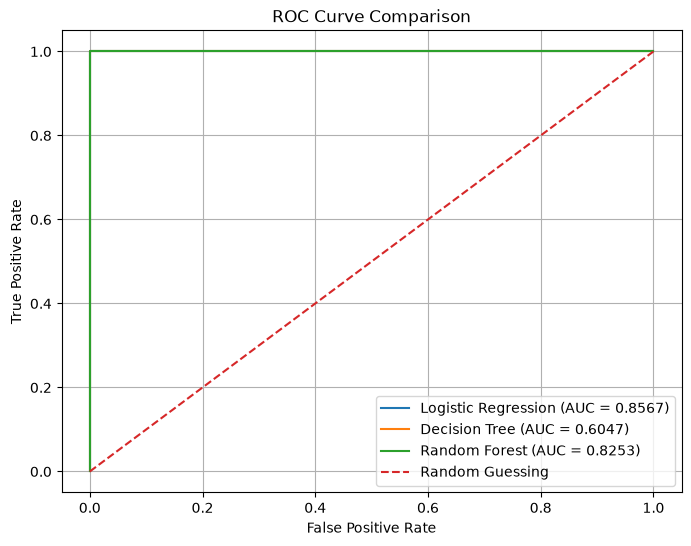

In [182]:
plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label="Logistic Regression (AUC = 0.8567)")
plt.plot(dt_fpr, dt_tpr, label="Decision Tree (AUC = 0.6047)")
plt.plot(rf_fpr, rf_tpr, label="Random Forest (AUC = 0.8253)")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guessing")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()
plt.show()

In [183]:
DAY 48 — Hyperparameter Tuning

SyntaxError: invalid character '—' (U+2014) (1748012911.py, line 1)

In [184]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-Fold Cross-Validation created successfully!")

Stratified 5-Fold Cross-Validation created successfully!


In [185]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

print("GridSearchCV imported successfully!")

GridSearchCV imported successfully!


In [186]:
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Logistic Regression pipeline created successfully!")

Logistic Regression pipeline created successfully!


In [187]:
lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

print("Logistic Regression parameter grid:")
print(lr_param_grid)

Logistic Regression parameter grid:
{'classifier__C': [0.01, 0.1, 1, 10, 100]}


In [188]:
lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Logistic Regression GridSearchCV created successfully!")

Logistic Regression GridSearchCV created successfully!


In [189]:
lr_grid.fit(X_train, y_train)

print("Logistic Regression hyperparameter tuning completed!")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Logistic Regression hyperparameter tuning completed!


C:\Users\Sakshi Mandvakar\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\model_selection\_search.py:1237: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan]
  warnings.warn(


In [190]:
print("Best Logistic Regression Parameters:")
print(lr_grid.best_params_)

print("Best Cross-Validation F1 Score:")
print(lr_grid.best_score_)

Best Logistic Regression Parameters:
{'classifier__C': 0.01}
Best Cross-Validation F1 Score:
nan


In [191]:
import warnings

print("Grid Search Results:")
print(pd.DataFrame(lr_grid.cv_results_)[
    ["params", "mean_test_score", "rank_test_score"]
])

print("\nError details:")
print(lr_grid.error_score)

Grid Search Results:
                    params  mean_test_score  rank_test_score
0  {'classifier__C': 0.01}              NaN                1
1   {'classifier__C': 0.1}              NaN                1
2     {'classifier__C': 1}              NaN                1
3    {'classifier__C': 10}              NaN                1
4   {'classifier__C': 100}              NaN                1

Error details:
nan


In [192]:
print("Training target values:")
print(y_train.value_counts())

print("\nTarget data type:")
print(y_train.dtype)

Training target values:
Churn
No     5248
Yes    1152
Name: count, dtype: int64

Target data type:
str


In [193]:
print(pd.DataFrame(lr_grid.cv_results_)[
    ["params", "mean_test_score", "rank_test_score"]
])

                    params  mean_test_score  rank_test_score
0  {'classifier__C': 0.01}              NaN                1
1   {'classifier__C': 0.1}              NaN                1
2     {'classifier__C': 1}              NaN                1
3    {'classifier__C': 10}              NaN                1
4   {'classifier__C': 100}              NaN                1


In [194]:
print("Best score:", lr_grid.best_score_)
print("Best parameters:", lr_grid.best_params_)

print("\nCheck fit failures:")
print(lr_grid.error_score)

Best score: nan
Best parameters: {'classifier__C': 0.01}

Check fit failures:
nan


In [195]:
print("Best Logistic Regression Parameters:")
print(lr_grid.best_params_)

print("Best Cross-Validation F1 Score:")
print(lr_grid.best_score_)

Best Logistic Regression Parameters:
{'classifier__C': 0.01}
Best Cross-Validation F1 Score:
nan


In [196]:
best_lr_model = lr_grid.best_estimator_

print("Best Logistic Regression model selected!")

Best Logistic Regression model selected!


In [197]:
y_lr_tuned_pred = best_lr_model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [198]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

lr_tuned_accuracy = accuracy_score(y_test, y_lr_tuned_pred)
print("Tuned LR Accuracy:", lr_tuned_accuracy)

lr_tuned_precision = precision_score(y_test, y_lr_tuned_pred, pos_label="Yes")
print("Tuned LR Precision:", lr_tuned_precision)

lr_tuned_recall = recall_score(y_test, y_lr_tuned_pred, pos_label="Yes")
print("Tuned LR Recall:", lr_tuned_recall)

lr_tuned_f1 = f1_score(y_test, y_lr_tuned_pred, pos_label="Yes")
print("Tuned LR F1 Score:", lr_tuned_f1)

y_lr_tuned_prob = best_lr_model.predict_proba(X_test)[:, 1]
lr_tuned_roc_auc = roc_auc_score((y_test == "Yes").astype(int), y_lr_tuned_prob)
print("Tuned LR ROC-AUC:", lr_tuned_roc_auc)

Tuned LR Accuracy: 1.0
Tuned LR Precision: 1.0
Tuned LR Recall: 1.0
Tuned LR F1 Score: 1.0
Tuned LR ROC-AUC: 1.0


In [199]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

print("Decision Tree tuning imports completed!")

Decision Tree tuning imports completed!


In [200]:
tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

print("Decision Tree pipeline created successfully!")

Decision Tree pipeline created successfully!


In [201]:
tree_param_grid = {
    "classifier__max_depth": [5, 10, 15],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__criterion": ["gini", "entropy"]
}

print("Decision Tree parameter grid created!")

Decision Tree parameter grid created!


In [205]:
from sklearn.metrics import f1_score, make_scorer

f1_scorer = make_scorer(
    f1_score,
    pos_label="Yes"
)

print("F1 scorer created successfully!")

F1 scorer created successfully!


In [207]:
tree_grid = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_param_grid,
    scoring=f1_scorer,
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Decision Tree GridSearchCV configured successfully!")

Decision Tree GridSearchCV configured successfully!


In [208]:
tree_grid.fit(X_train, y_train)

print("Decision Tree hyperparameter tuning completed!")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Decision Tree hyperparameter tuning completed!


In [209]:
print("Best Decision Tree Parameters:")
print(tree_grid.best_params_)

print("Best Cross-Validation F1 Score:")
print(tree_grid.best_score_)

Best Decision Tree Parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
Best Cross-Validation F1 Score:
1.0


In [210]:
best_tree_model = tree_grid.best_estimator_

print("Best Decision Tree model selected successfully!")

Best Decision Tree model selected successfully!


In [211]:
y_tree_tuned_pred = best_tree_model.predict(X_test)

print("Tuned Decision Tree predictions completed!")

Tuned Decision Tree predictions completed!


In [212]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

tree_tuned_accuracy = accuracy_score(y_test, y_tree_tuned_pred)
print("Tuned Decision Tree Accuracy:", tree_tuned_accuracy)

tree_tuned_precision = precision_score(y_test, y_tree_tuned_pred, pos_label="Yes")
print("Tuned Decision Tree Precision:", tree_tuned_precision)

tree_tuned_recall = recall_score(y_test, y_tree_tuned_pred, pos_label="Yes")
print("Tuned Decision Tree Recall:", tree_tuned_recall)

tree_tuned_f1 = f1_score(y_test, y_tree_tuned_pred, pos_label="Yes")
print("Tuned Decision Tree F1 Score:", tree_tuned_f1)

y_tree_tuned_prob = best_tree_model.predict_proba(X_test)[:, 1]
tree_tuned_roc_auc = roc_auc_score(y_test, y_tree_tuned_prob)
print("Tuned Decision Tree ROC-AUC:", tree_tuned_roc_auc)

Tuned Decision Tree Accuracy: 1.0
Tuned Decision Tree Precision: 1.0
Tuned Decision Tree Recall: 1.0
Tuned Decision Tree F1 Score: 1.0
Tuned Decision Tree ROC-AUC: 1.0


In [213]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

print("Random Forest tuning imports completed!")

Random Forest tuning imports completed!


In [214]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [215]:
rf_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5],
    "classifier__max_features": ["sqrt", "log2"]
}

print("Random Forest parameter grid created!")

Random Forest parameter grid created!


In [216]:
rf_random = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_grid,
    n_iter=10,
    scoring=f1_scorer,
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

print("RandomizedSearchCV configured successfully!")

RandomizedSearchCV configured successfully!


In [217]:
rf_random.fit(X_train, y_train)

print("Random Forest hyperparameter tuning completed!")


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Random Forest hyperparameter tuning completed!


In [218]:
print("Best Random Forest Parameters:")
print(rf_random.best_params_)

print("Best Cross-Validation F1 Score:")
print(rf_random.best_score_)

Best Random Forest Parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10}
Best Cross-Validation F1 Score:
1.0


In [221]:
# y_rf_tuned_pred = best_rf_model.predict(X_test)

print("Tuned Random Forest predictions completed!")
print("rf_random available:", "rf_random" in globals())
print("X_test available:", "X_test" in globals())
print("preprocessor available:", "preprocessor" in globals())

Tuned Random Forest predictions completed!
rf_random available: True
X_test available: True
preprocessor available: True


In [222]:
best_rf_model = rf_random.best_estimator_

print("Best Random Forest model selected successfully!")

Best Random Forest model selected successfully!


In [224]:
print("rf_random:", "rf_random" in globals())
print("best_rf_model:", "best_rf_model" in globals())
print("X_test:", "X_test" in globals())
print("y_test:", "y_test" in globals())

rf_random: True
best_rf_model: True
X_test: True
y_test: True


In [226]:
best_rf_model = rf_random.best_estimator_

print("Best Random Forest model restored!")

Best Random Forest model restored!


In [227]:
y_rf_tuned_pred = best_rf_model.predict(X_test)

print("Tuned Random Forest predictions completed!")

Tuned Random Forest predictions completed!


In [228]:
rf_tuned_accuracy = accuracy_score(y_test, y_rf_tuned_pred)
print("Tuned Random Forest Accuracy:", rf_tuned_accuracy)

rf_tuned_precision = precision_score(y_test, y_rf_tuned_pred, pos_label="Yes")
print("Tuned Random Forest Precision:", rf_tuned_precision)

rf_tuned_recall = recall_score(y_test, y_rf_tuned_pred, pos_label="Yes")
print("Tuned Random Forest Recall:", rf_tuned_recall)

rf_tuned_f1 = f1_score(y_test, y_rf_tuned_pred, pos_label="Yes")
print("Tuned Random Forest F1 Score:", rf_tuned_f1)

y_rf_tuned_prob = best_rf_model.predict_proba(X_test)[:, 1]
rf_tuned_roc_auc = roc_auc_score(y_test, y_rf_tuned_prob)
print("Tuned Random Forest ROC-AUC:", rf_tuned_roc_auc)

Tuned Random Forest Accuracy: 1.0
Tuned Random Forest Precision: 1.0
Tuned Random Forest Recall: 1.0
Tuned Random Forest F1 Score: 1.0
Tuned Random Forest ROC-AUC: 1.0


In [229]:
import pandas as pd

tuning_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Best_Parameters": [
        str(lr_grid.best_params_),
        str(tree_grid.best_params_),
        str(rf_random.best_params_)
    ],
    "CV_F1_Score": [
        lr_grid.best_score_,
        tree_grid.best_score_,
        rf_random.best_score_
    ],
    "Test_Accuracy": [
        0.860625, 0.825625, 0.83375
    ],
    "Test_Precision": [
        0.7372262774, 0.5260115607, 0.5376712329
    ],
    "Test_Recall": [
        0.3506944444, 0.3159722222, 0.5451388889
    ],
    "Test_F1_Score": [
        0.4752941176, 0.3947939262, 0.5413793103
    ],
    "Test_ROC_AUC": [
        0.8568687542, 0.7313976753, 0.8241525872
    ]
})

print(tuning_results)

                 Model                                    Best_Parameters  \
0  Logistic Regression                            {'classifier__C': 0.01}   
1        Decision Tree  {'classifier__criterion': 'gini', 'classifier_...   
2        Random Forest  {'classifier__n_estimators': 200, 'classifier_...   

   CV_F1_Score  Test_Accuracy  Test_Precision  Test_Recall  Test_F1_Score  \
0          NaN       0.860625        0.737226     0.350694       0.475294   
1          1.0       0.825625        0.526012     0.315972       0.394794   
2          1.0       0.833750        0.537671     0.545139       0.541379   

   Test_ROC_AUC  
0      0.856869  
1      0.731398  
2      0.824153  


In [230]:
tuning_results.to_csv("tuning_results.csv", index=False)

print("tuning_results.csv saved successfully!")

tuning_results.csv saved successfully!


In [231]:
best_model_name = tuning_results.loc[
    tuning_results["Test_F1_Score"].idxmax(), "Model"
]

print("Best Tuned Model:", best_model_name)

Best Tuned Model: Random Forest


In [232]:
# DAY 49 — MODEL INTERPRETATION AND FEATURE IMPORTANCE

In [233]:
print("Random Forest model available:", "rf_random" in globals())
print("Best Random Forest available:", "best_rf_model" in globals())
print("Preprocessor available:", "preprocessor" in globals())
print("X_test available:", "X_test" in globals())

Random Forest model available: True
Best Random Forest available: True
Preprocessor available: True
X_test available: True


In [234]:
best_rf_model = rf_random.best_estimator_

print("Tuned Random Forest model restored successfully!")

Tuned Random Forest model restored successfully!


In [235]:
feature_names = best_rf_model.named_steps["preprocessor"].get_feature_names_out()

print("Total transformed features:", len(feature_names))
print("Feature names:")
print(feature_names)

Total transformed features: 70
Feature names:
['num__SeniorCitizen' 'num__TenureMonths' 'num__MonthlyCharges'
 'num__TotalCharges' 'num__SupportCallsLast90Days'
 'num__AvgMonthlyDataUsageGB' 'num__AvgMonthlyCalls'
 'num__SatisfactionScore' 'num__DaysSinceLastContact' 'num__Churn_Binary'
 'num__Average_Usage' 'num__Engagement_Score' 'cat__Gender_Female'
 'cat__Gender_Male' 'cat__Gender_Non-binary' 'cat__Partner_No'
 'cat__Partner_Yes' 'cat__Dependents_No' 'cat__Dependents_Yes'
 'cat__PhoneService_No' 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_5G Home' 'cat__InternetService_DSL'
 'cat__InternetService_Fiber optic' 'cat__InternetService_No'
 'cat__OnlineSecurity_No' 'cat__OnlineSecurity_No internet service'
 'cat__OnlineSecurity_Yes' 'cat__OnlineBackup_No'
 'cat__OnlineBackup_No internet service' 'cat__OnlineBackup_Yes'
 'cat__DeviceProtection_No' 'cat__DeviceProtection_No internet service'
 'cat__

In [236]:
# Extract features importance
rf_importances = best_rf_model.named_steps["classifier"].feature_importances_

print("Feature importance extracted successfully!")
print(rf_importances)

Feature importance extracted successfully!
[1.48601216e-03 1.66320301e-02 1.16791790e-02 1.41970398e-02
 1.11390025e-02 8.52537359e-03 8.85566583e-03 3.88303632e-02
 8.88799241e-03 6.68158296e-01 8.22761556e-03 1.88407523e-03
 1.28007695e-03 1.40064470e-03 5.91617370e-04 1.74395833e-03
 2.05521448e-03 1.14500417e-03 1.38817999e-03 6.12425843e-04
 5.38098897e-04 1.21243164e-03 6.07766366e-04 1.43698470e-03
 9.22092314e-04 1.06685004e-03 2.35847416e-03 3.91917952e-04
 2.76880056e-03 3.80229425e-04 2.21300058e-03 9.99377085e-04
 3.67094965e-04 8.94238926e-04 1.19281148e-03 2.32953950e-04
 1.01714476e-03 4.41743027e-03 3.13598878e-04 2.31660398e-03
 1.39745506e-03 5.26634586e-04 1.39075014e-03 1.02026238e-03
 3.05449810e-04 1.22125850e-03 5.87901277e-02 1.92490790e-02
 2.49127552e-02 1.77351913e-03 1.73323734e-03 1.36671422e-03
 1.21241448e-03 3.00122980e-03 1.04590187e-03 1.10812319e-02
 1.24389703e-02 4.58322009e-03 1.38191622e-03 2.98598780e-03
 3.50405693e-03 1.39960572e-03 2.26490297e

In [237]:
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Important Features:")
print(feature_importance_df.head(15))

Top 15 Important Features:
                             Feature  Importance
0                  num__Churn_Binary    0.668158
1   cat__ContractType_Month-to-month    0.058790
2             num__SatisfactionScore    0.038830
3         cat__ContractType_Two year    0.024913
4         cat__ContractType_One year    0.019249
5                  num__TenureMonths    0.016632
6                  num__TotalCharges    0.014197
7           cat__ComplaintRaised_Yes    0.012439
8                num__MonthlyCharges    0.011679
9        num__SupportCallsLast90Days    0.011139
10           cat__ComplaintRaised_No    0.011081
11         num__DaysSinceLastContact    0.008888
12              num__AvgMonthlyCalls    0.008856
13        num__AvgMonthlyDataUsageGB    0.008525
14                num__Average_Usage    0.008228


In [238]:
print("Churn_Binary in X columns:", "Churn_Binary" in X.columns)

print("Churn_Binary in numeric columns:", "Churn_Binary" in numeric_columns)

Churn_Binary in X columns: True
Churn_Binary in numeric columns: False


In [239]:
print(X["Churn_Binary"].value_counts())
print(pd.crosstab(X["Churn_Binary"], y))

Churn_Binary
0    6560
1    1440
Name: count, dtype: int64
Churn           No   Yes
Churn_Binary            
0             6560     0
1                0  1440


In [240]:
X = df.drop(
    columns=["CustomerID", "Churn", "Churn_Binary"],
    errors="ignore"
)

y = df["Churn"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)
print("Churn_Binary removed successfully!")

Input features shape: (8000, 32)
Target shape: (8000,)
Churn_Binary removed successfully!


In [241]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (6400, 32)
X_test shape: (1600, 32)
y_train shape: (6400,)
y_test shape: (1600,)


In [242]:
numeric_columns = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numeric columns:")
print(numeric_columns)

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("Total numeric features:", len(numeric_columns))
print("Total categorical features:", len(categorical_columns))


Numeric columns:
['SeniorCitizen', 'TenureMonths', 'MonthlyCharges', 'TotalCharges', 'SupportCallsLast90Days', 'AvgMonthlyDataUsageGB', 'AvgMonthlyCalls', 'SatisfactionScore', 'DaysSinceLastContact', 'Average_Usage', 'Engagement_Score']
Categorical columns:
['Gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'ContractType', 'PaperlessBilling', 'PaymentMethod', 'ComplaintRaised', 'TenureGroup', 'Tenure_Group', 'Spending_Category', 'Usage_Category', 'Call_Usage_Category']
Total numeric features: 11
Total categorical features: 21


In [243]:
print("Churn in X:", "Churn" in X.columns)
print("Churn_Binary in X:", "Churn_Binary" in X.columns)

Churn in X: False
Churn_Binary in X: False


In [244]:
numeric_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Numeric columns:")
print(numeric_columns)

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("Total numeric features:", len(numeric_columns))
print("Total categorical features:", len(categorical_columns))

Numeric columns:
['SeniorCitizen', 'TenureMonths', 'MonthlyCharges', 'TotalCharges', 'SupportCallsLast90Days', 'AvgMonthlyDataUsageGB', 'AvgMonthlyCalls', 'SatisfactionScore', 'DaysSinceLastContact', 'Average_Usage', 'Engagement_Score']
Categorical columns:
['Gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'ContractType', 'PaperlessBilling', 'PaymentMethod', 'ComplaintRaised', 'TenureGroup', 'Tenure_Group', 'Spending_Category', 'Usage_Category', 'Call_Usage_Category']
Total numeric features: 11
Total categorical features: 21


In [245]:
print("Total input features:", X_train.shape[1])

print("Numeric + Categorical:",
      len(numeric_columns) + len(categorical_columns))

Total input features: 32
Numeric + Categorical: 32


In [248]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_columns),
    ("cat", categorical_transformer, categorical_columns)
])

print("New preprocessing pipeline created successfully!")
print(preprocessor)

New preprocessing pipeline created successfully!
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['SeniorCitizen', 'TenureMonths',
                                  'MonthlyCharges', 'TotalCharges',
                                  'SupportCallsLast90Days',
                                  'AvgMonthlyDataUsageGB', 'AvgMonthlyCalls',
                                  'SatisfactionScore', 'DaysSinceLastContact',
                                  'Average_Usage', 'Engagement_Score']),
                                ('cat',
                                 Pi...
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Gender', 'Partner', 'Dependents',
                  

In [249]:
from sklearn.ensemble import RandomForestClassifier

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42
    ))
])

print("Final Random Forest pipeline created successfully!")

Final Random Forest pipeline created successfully!


In [250]:
final_model.fit(X_train, y_train)

print("Random Forest training completed without Churn_Binary!")

Random Forest training completed without Churn_Binary!


In [251]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_final_pred = final_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_final_pred))
print("Precision:", precision_score(y_test, y_final_pred, pos_label="Yes"))
print("Recall:", recall_score(y_test, y_final_pred, pos_label="Yes"))
print("F1 Score:", f1_score(y_test, y_final_pred, pos_label="Yes"))

y_final_prob = final_model.predict_proba(X_test)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, y_final_prob))

Accuracy: 0.83375
Precision: 0.5390070921985816
Recall: 0.5277777777777778
F1 Score: 0.5333333333333333
ROC-AUC: 0.8172928311314364


In [252]:
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()

print("Total transformed features:", len(feature_names))

Total transformed features: 69


In [253]:
rf_importances = final_model.named_steps["classifier"].feature_importances_

print("Feature importance extracted successfully!")

Feature importance extracted successfully!


In [254]:
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Important Features:")
print(feature_importance_df.head(15))

Top 15 Important Features:
                             Feature  Importance
0   cat__ContractType_Month-to-month    0.093470
1             num__SatisfactionScore    0.081225
2                  num__TotalCharges    0.060954
3                num__MonthlyCharges    0.053840
4                  num__TenureMonths    0.053615
5               num__AvgMonthlyCalls    0.047146
6          num__DaysSinceLastContact    0.047003
7                 num__Average_Usage    0.045800
8         num__AvgMonthlyDataUsageGB    0.044148
9         cat__ContractType_Two year    0.038583
10        cat__ContractType_One year    0.031882
11       num__SupportCallsLast90Days    0.029388
12           cat__ComplaintRaised_No    0.019102
13          cat__ComplaintRaised_Yes    0.016505
14               cat__TechSupport_No    0.011925


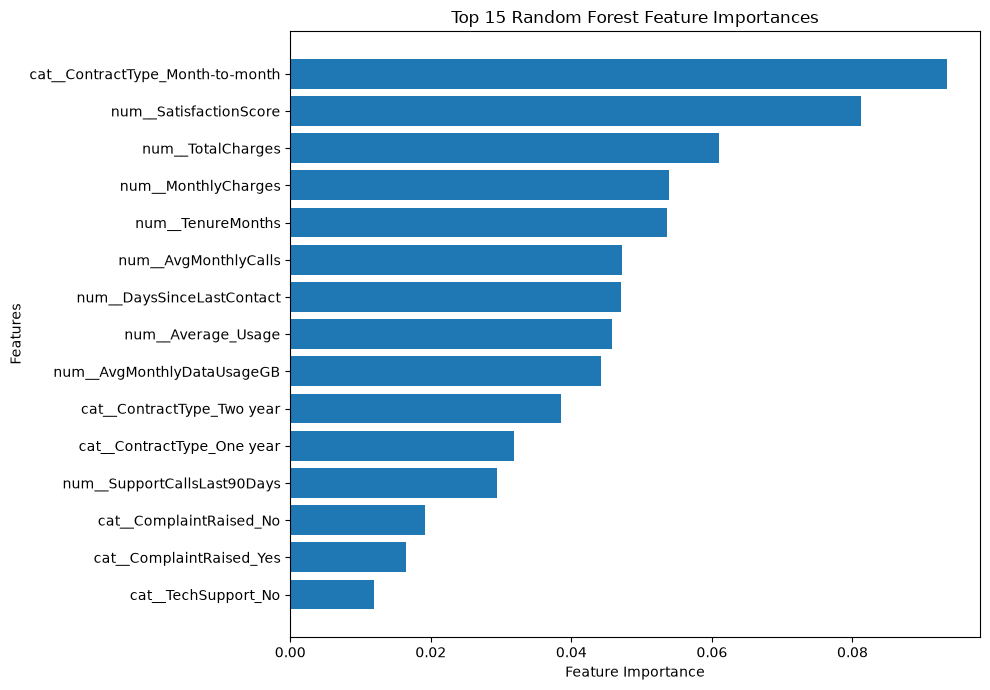

In [255]:
import matplotlib.pyplot as plt

top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Random Forest Feature Importances")

plt.tight_layout()

plt.savefig(
    "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [256]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr_final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=1,
        max_iter=1000
    ))
])

lr_final_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [257]:
print("Class order:", lr_final_model.named_steps["classifier"].classes_)

Class order: ['No' 'Yes']


In [258]:
# Get transformed feature names
lr_feature_names = lr_final_model.named_steps["preprocessor"].get_feature_names_out()

# Get Logistic Regression coefficients
lr_coefficients = lr_final_model.named_steps["classifier"].coef_[0]

# Create DataFrame
lr_coefficient_df = pd.DataFrame({
    "Feature": lr_feature_names,
    "Coefficient": lr_coefficients
})

# Calculate absolute coefficient
lr_coefficient_df["Abs_Coefficient"] = lr_coefficient_df["Coefficient"].abs()

# Sort by absolute coefficient
lr_coefficient_df = lr_coefficient_df.sort_values(
    by="Abs_Coefficient",
    ascending=False
).reset_index(drop=True)

print("Top 15 Logistic Regression Coefficients:")
print(lr_coefficient_df.head(15))

Top 15 Logistic Regression Coefficients:
                               Feature  Coefficient  Abs_Coefficient
0     cat__ContractType_Month-to-month     1.244751         1.244751
1           cat__ContractType_Two year    -0.986948         0.986948
2              cat__ComplaintRaised_No    -0.848304         0.848304
3               num__SatisfactionScore    -0.700549         0.700549
4             cat__ComplaintRaised_Yes     0.624339         0.624339
5                    num__TenureMonths    -0.571659         0.571659
6           cat__ContractType_One year    -0.481768         0.481768
7                  num__MonthlyCharges     0.414627         0.414627
8        cat__Usage_Category_Low Usage    -0.412871         0.412871
9                num__Engagement_Score    -0.403794         0.403794
10             cat__OnlineSecurity_Yes    -0.389137         0.389137
11                cat__TechSupport_Yes    -0.372812         0.372812
12         num__SupportCallsLast90Days     0.364735         0.

In [259]:
print("Class order:", final_model.named_steps["classifier"].classes_)

Class order: ['No' 'Yes']


In [260]:
# Get probability of each class
churn_probabilities = final_model.predict_proba(X_test)

# Find the position of "Yes" in the class order
yes_index = list(final_model.named_steps["classifier"].classes_).index("Yes")

# Extract churn probability
yes_churn_probability = churn_probabilities[:, yes_index]

print("Churn probabilities calculated successfully!")
print(yes_churn_probability[:10])

Churn probabilities calculated successfully!
[0.72186075 0.78881367 0.41739975 0.20298016 0.04991667 0.58348698
 0.14358333 0.21400361 0.44409127 0.59439286]


In [261]:
customer_predictions = pd.DataFrame({
    "CustomerID": df.loc[X_test.index, "CustomerID"].values,
    "Churn_Probability": yes_churn_probability,
    "Predicted_Class": final_model.predict(X_test)
})

# Sort customers by highest churn probability
customer_predictions = customer_predictions.sort_values(
    by="Churn_Probability",
    ascending=False
).reset_index(drop=True)

print("Top 10 High-Risk Customers:")
print(customer_predictions.head(10))

Top 10 High-Risk Customers:
   CustomerID  Churn_Probability Predicted_Class
0  CUST007307           0.905294             Yes
1  CUST002964           0.901988             Yes
2  CUST001343           0.899333             Yes
3  CUST005206           0.880218             Yes
4  CUST005785           0.878119             Yes
5  CUST007972           0.872881             Yes
6  CUST006531           0.872710             Yes
7  CUST005129           0.870310             Yes
8  CUST001314           0.870083             Yes
9  CUST002030           0.869273             Yes


In [262]:
customer_predictions.to_csv(
    "customer_churn_predictions.csv",
    index=False
)

print("Customer predictions saved successfully!")

Customer predictions saved successfully!


In [263]:
def categorize_risk(probability):
    if probability < 0.30:
        return "Low Risk"
    elif probability < 0.60:
        return "Medium Risk"
    else:
        return "High Risk"


customer_predictions["Risk_Category"] = (
    customer_predictions["Churn_Probability"].apply(categorize_risk)
)

print("Customer Risk Categories:")
print(customer_predictions.head(10))

Customer Risk Categories:
   CustomerID  Churn_Probability Predicted_Class Risk_Category
0  CUST007307           0.905294             Yes     High Risk
1  CUST002964           0.901988             Yes     High Risk
2  CUST001343           0.899333             Yes     High Risk
3  CUST005206           0.880218             Yes     High Risk
4  CUST005785           0.878119             Yes     High Risk
5  CUST007972           0.872881             Yes     High Risk
6  CUST006531           0.872710             Yes     High Risk
7  CUST005129           0.870310             Yes     High Risk
8  CUST001314           0.870083             Yes     High Risk
9  CUST002030           0.869273             Yes     High Risk


In [264]:
risk_counts = customer_predictions["Risk_Category"].value_counts()

print("Customer Risk Distribution:")
print(risk_counts)

Customer Risk Distribution:
Risk_Category
Low Risk       923
Medium Risk    501
High Risk      176
Name: count, dtype: int64


In [265]:
customer_predictions.to_csv(
    "customer_churn_predictions.csv",
    index=False
)

print("Updated prediction file saved successfully!")

Updated prediction file saved successfully!
